# 🧮 13_ml_features_itens — Engenharia de features da base de itens
**Squad 2 · Eduardo e Aliedson** · ML em streaming · **base da etapa 1: itens** · problema da dupla: **P1 · previsão de vendas da tarde**

### 🎯 Tarefa 2 · Engenharia de features
> *Preparar os dados para o modelo. Criar colunas numéricas que ajudem a identificar padrões.*

| O que foi pedido | Onde neste notebook |
|---|---|
| Preparar os dados para o modelo | Etapas 1 a 7 (criam e gravam as 3 tabelas) · 2.1 · 2.5 · 2.7 |
| Criar colunas numéricas | Etapas 3 a 6 · 2.2 Dicionário de features |
| Transformar categóricas em numéricas e normalizar (orientação do Geovany) | Etapa 8 · Codificação e normalização |
| Que ajudem a identificar padrões | 2.3 · 2.4 · 2.6 |
| Conferir tudo contra o que foi pedido (tarefas + planilha `machine_learning_squad_2`) | 2.8 Validação |

Transforma os itens em **colunas numéricas** prontas para o modelo, seguindo o que a EDA mostrou (`12_ml_eda_itens`):
o `valor_total` do pedido é **Σ quantidade × (preço − desconto por unidade)** (o frete não entra), há itens com quantidade, preço ou desconto inválidos,
e o mix de categorias muda entre manhã e tarde.

| Tabela gerada | Uma linha por | Para quê |
|---|---|---|
| `ml_features_itens_pedido` | pedido | perfil da cesta (P1, P3) e lista de SKUs (P2) |
| `ml_features_itens_hora` | data + hora (Brasília) | features por hora do P1: volume, receita, mix, lags de 1 a 24h, média móvel e calendário |
| `ml_features_p1_dia` | dia | o que se sabe da **manhã até 12h** + alvo da **tarde** (receita e nº de pedidos) |
| `ml_modelo_itens_pedido` · `ml_modelo_itens_hora` · `ml_modelo_p1_dia` | igual às anteriores | **entrada do modelo**: só números, categóricas em 0/1 e numéricas normalizadas |

### Features geradas (resumo)
| Grupo | Features | Lógica |
|---|---|---|
| Valor do item | `valor_bruto`, `desconto_item`, `valor_liquido` | quantidade × preço; quantidade × desconto; bruto − desconto (= `valor_total`) |
| Atributos do produto | `marca`, `tamanho_embalagem`, `item_por_peso` | marca do catálogo (ou 2ª parte do `sku`); 3ª parte do `sku` (`categoria-marca-tamanho`); unidade de medida em peso ou quantidade fracionada |
| Por pedido | `n_itens`, `n_skus`, `n_marcas`, `n_categorias`, `valor_liquido`, `valor_medio_item`, `pct_desconto`, `pct_itens_por_peso`, `categoria_dominante`, `marca_dominante`, mix | contagens, somas e participações dos itens do pedido |
| Por hora (P1) | `receita`, `pedidos`, `ticket_medio`, `itens_por_pedido`, `pct_valor_<categoria>`, lags de 1 a 24h, média móvel, `hora`, `dia_semana` | só pedidos aprovados; hora sem micro-lote = vazio |
| Por dia (P1) | features da manhã + `alvo_receita_tarde`, `alvo_pedidos_tarde` | manhã = o que chegou até 12h; alvo = 12h às 17:59 |

| Etapa | O que faz |
|---|---|
| 1 | Configuração |
| 2 | Leitura dos micro-lotes e dos pedidos aprovados (Silver) |
| 3 | Itens enriquecidos: valores, categoria, hora e marcação de itens inválidos |
| 4 | Features por pedido |
| 5 | Features por hora (grade completa, lags e calendário) |
| 6 | Features do P1 por dia (manhã → tarde) |
| 7 | Gravação em Delta e conferência |
| 8 | **Codificação e normalização**: categóricas → 0/1 (one-hot), numéricas padronizadas; grava as tabelas `ml_modelo_*` |
| 2.1 – 2.7 | **Análise das features**: do dado à feature, dicionário, por pedido, por hora, por dia, padrões e prontidão |
| 2.8 | **Validação**: o que foi pedido (tarefas + planilha) × o que entregamos |
| 3 | Conclusões, decisão necessária e próximos passos |
| 4 | **Relatório completo** (EDA + features) em `docs/13_ml_features_itens/` |

**Regras das features:** receita = soma do `valor_total` dos pedidos **aprovados (Silver)**; o mix e as médias dos itens usam só itens válidos;
hora **sem micro-lote** fica vazia (dado desconhecido), hora com micro-lote e sem pedido vale 0; a manhã usa só micro-lotes gerados **antes das 12h**.
Cada etapa **faz** e **valida**: ✅ ok · ⚠️ achado (segue) · ❌ erro (para).
**Ordem:** rode antes o `12_ml_eda_itens` (Tarefa 1); este notebook usa o registro dele para o relatório completo.

📘 **Documentação completa:** última célula deste notebook.

## Etapa 1 — Configuração
**Faz:** carrega o `00_setup_config` e define os parâmetros das features e onde gravar.
**Valida:** se as funções necessárias existem e se a Silver de pedidos existe. Carrega também os resultados da EDA (`docs/12_ml_eda_itens/registro_eda.json`) para a validação e o relatório.

In [0]:
VALIDACAO_COMPLETA = False

In [0]:
%run ./00_setup_config

# ⚙️ 00_setup_config — Configuração central
**Squad 2 · Dupla 3 · `ecommerce_pedidos`**

Prepara endereços, credenciais, conexões e funções usadas por todo o pipeline. **Não lê nem grava pedidos.**

Cada etapa **faz o trabalho e valida em seguida**: ✅ ok · ⚠️ aviso (segue) · ❌ erro (para e explica).

**Uso nos outros notebooks** (duas células; o `%run` fica sozinho):
```
VALIDACAO_COMPLETA = False
```
```
%run ./00_setup_config
```
Dependências em **Environment → Dependencies**: `azure-identity`, `azure-storage-file-datalake`.

## Etapa 1 — Ambiente e endereços
**Faz:** cria a função `checar` e guarda os nomes fixos do projeto.
**Valida:** se está no Databricks e se origem e destino são containers diferentes.

Modo de validação: RÁPIDA
✅ Rodando no Databricks
✅ Origem (raw) e destino (squad2) separados


## Etapa 2 — Credenciais
**Faz:** busca as 7 chaves no Secret Scope. Ficam só na memória (aparecem como `[REDACTED]` se impressas).
**Valida:** se o cofre existe, se nenhuma chave falta e se o host do SQL tem o formato certo.

✅ Cofre 'mercadata-ecommerce-pedidos' encontrado
✅ 7 credenciais carregadas (valores ocultos)
✅ SQL_HOST no formato do Azure SQL


## Etapa 3 — Conexões com o Data Lake
**Faz:** cria o cliente do SDK (`fs_origem`, `fs_squad`) e as credenciais do Spark (`adls_options`).
**Valida:** acesso de leitura ao `raw`, acesso ao `squad2` e quais pastas de camada já existem.

... (5 outputs left out)

## Etapa 6 — Funções do SQL Server
**Faz:** cria as funções de gravar e consultar o banco. Gravação pelo conector `sqlserver` (o `jdbc` é bloqueado no Serverless); leitura pelo `jdbc`.
**Valida:** se toda tabela recebe o schema `squad2`.

✅ Tabelas SQL vão para o schema 'squad2'


## Etapa 7 — Teste completo (só ao rodar este notebook direto)
**Faz e valida:** varre o `raw` · lê o micro-lote mais recente e confere colunas e tipos (regra 1) · grava e relê em `metadata/` · `SELECT 1` no SQL Server · confere se o schema `squad2` existe no banco.
No modo rápido (`%run`), é pulada. No fim, limpa as variáveis temporárias.

Teste completo pulado (modo rápido).
⚙️ 00_setup_config pronto para uso


In [0]:
from concurrent.futures import ThreadPoolExecutor
import os, re, json, unicodedata, base64, time, html as html_lib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

FUSO_HORAS = int(((ler_metadata("eda_raw") or {}).get("fuso") or {}).get("horas_ate_utc", 3))   # gerador -> UTC (contrato da EDA)
AJUSTE_LOCAL_H = FUSO_HORAS - 3            # horas a somar ao horário do gerador para ler em Brasília
HORA_PREVISAO = 12                         # manhã = até 11:59 · tarde = 12h às 17:59 (P1)
FIM_TARDE = 18
MIN_HORAS_MANHA = 3                        # dia completo: as 6 horas da tarde com micro-lote e ao menos 3 horas da manhã (mesma regra do 12_ml_eda_itens)
DIAS_MINIMOS_TREINO = 14                   # dias completos mínimos para treinar e testar o P1 (2 semanas)
DIAS_SEMANA = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
TOP_CATEGORIAS = 8                         # categorias com coluna própria no mix; o resto vira "outras"
LAGS_H = list(range(1, 25))                        # lags por hora (24h = mesma hora do dia anterior, o baseline do P1)
JANELA_MEDIA_H = 3                         # média móvel das horas anteriores
TOLERANCIA_VALOR = 0.05                    # R$ aceitos entre a conta dos itens e o valor_total
DOWNLOADS = 16                             # micro-lotes baixados ao mesmo tempo
GRAVAR = True                              # False = só calcula e mostra, sem gravar
UNIDADES_PESO = {"kg", "g", "kilo", "quilo", "quilograma", "grama", "gramas"}   # unidade_medida de produto vendido por peso
REGISTRAR_CATALOGO = False                 # True = também grava cópias no Unity Catalog (consulta por nome via SQL) · combinar antes com o orientador
CATALOGO_SCHEMA = "workspace.squad2"       # catálogo.schema usado se REGISTRAR_CATALOGO = True
AGORA = pd.Timestamp.now(tz="America/Sao_Paulo").tz_localize(None)
INICIO = time.time()
PADRAO_JANELA = r"(\d{4}/\d{2}/\d{2}/\d{6})"
TABELAS = {"itens": "ecommerce_itens_pedido", "pedidos": "ecommerce_pedidos",
           "produtos": "ecommerce_produtos", "categorias": "ecommerce_categorias"}
DESTINOS = {"pedido": caminho_gold("ml_features_itens_pedido"),       # subpasta da nossa tabela no squad2 (gold/ecommerce_pedidos/)
            "hora": caminho_gold("ml_features_itens_hora"),
            "dia": caminho_gold("ml_features_p1_dia")}

# ------------------------------ padrão visual ------------------------------
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # ordem fixa das séries
CINZA, FUNDO, TEXTO_2 = "#a3a29c", "#fcfcfb", "#52514e"
OK_COR, ALERTA_COR, SERIO_COR, ERRO_COR = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"               # só para estado (ok/atenção/problema)
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]).with_extremes(bad=FUNDO)
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({"figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": CINZA, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "text.color": "#0b0b0b",
                     "font.size": 10, "legend.frameon": False, "text.parse_math": False})    # "R$" sem virar fórmula


def br(valor, casas=0):
    """Número no formato brasileiro (14.196 · 2,5)."""
    if valor is None or pd.isna(valor):
        return "—"
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


reais = lambda valor, casas=2: f"R$ {br(valor, casas)}"
pct = lambda valor, casas=1: "—" if valor is None or pd.isna(valor) else f"{br(valor, casas)}%"
dia_txt = lambda d: f"{pd.Timestamp(d):%d/%m} {DIAS_SEMANA[pd.Timestamp(d).dayofweek]}"


# ------------------------------ registro para o relatório (seção 4) ------------------------------
REGISTRO, SECAO_ATUAL = {}, None        # seção -> título, leituras, figuras, tabelas e cartões desta execução


def secao(codigo, titulo):
    """Marca a seção atual: leituras, gráficos e tabelas seguintes vão para ela no relatório."""
    global SECAO_ATUAL
    SECAO_ATUAL = codigo
    REGISTRO[codigo] = {"titulo": titulo, "leituras": [], "figuras": [], "tabelas": [], "cartoes": []}


def _registro():
    return REGISTRO.get(SECAO_ATUAL, {"leituras": [], "figuras": [], "tabelas": [], "cartoes": []})


def mostrar():
    """Mostra o gráfico e guarda uma cópia (PNG) para o relatório .html."""
    buffer = io.BytesIO()
    plt.gcf().savefig(buffer, format="png", dpi=100, bbox_inches="tight")
    _registro()["figuras"].append(base64.b64encode(buffer.getvalue()).decode())
    plt.show()


def exibir(tabela, nome, linhas=25):
    """display() + guarda a tabela (primeiras linhas) para o relatório."""
    display(tabela)
    _registro()["tabelas"].append((nome, tabela.head(linhas).copy()))


def selo(ok, grave=False):
    return "✅ ok" if ok else ("❌ bloqueia" if grave else "⚠️ atenção")


def cartoes(lista):
    """Números-chave em cartões. lista de (rótulo, valor, nota, estado) · estado: 'ok', 'alerta', 'erro' ou None."""
    borda = {"ok": OK_COR, "alerta": ALERTA_COR, "erro": ERRO_COR, None: "#d6d5d0"}
    icone = {"ok": "✅ ", "alerta": "⚠️ ", "erro": "❌ ", None: ""}
    blocos = "".join(
        f'<div style="background:#fcfcfb;border:1px solid #e4e3df;border-left:5px solid {borda[e]};border-radius:8px;padding:12px 14px">'
        f'<div style="color:#52514e;font-size:12px">{icone[e]}{r}</div>'
        f'<div style="color:#0b0b0b;font-size:24px;font-weight:700;margin:4px 0">{v}</div>'
        f'<div style="color:#6b6a65;font-size:12px">{n}</div></div>' for r, v, n, e in lista)
    html = (f'<div style="display:grid;grid-template-columns:repeat(auto-fill,minmax(210px,1fr));gap:10px;'
            f'font-family:-apple-system,Segoe UI,Roboto,sans-serif">{blocos}</div>')
    _registro()["cartoes"] = list(lista)
    if "displayHTML" in globals():
        displayHTML(html)
    else:
        for r, v, n, e in lista:
            print(f"{icone[e]}{r}: {v} · {n}")


def leitura(*linhas):
    """Conclusões calculadas desta execução, logo abaixo de um gráfico ou tabela."""
    print("📌 Leitura")
    for linha in linhas:
        print(f"   • {linha}")
    _registro()["leituras"].extend(linhas)


def rotular(eixo, barras, textos, horizontal=False):
    for barra, texto in zip(barras, textos):
        if horizontal:
            eixo.annotate(texto, (barra.get_width(), barra.get_y() + barra.get_height() / 2), xytext=(4, 0),
                          textcoords="offset points", va="center", fontsize=8, color=TEXTO_2)
        else:
            eixo.annotate(texto, (barra.get_x() + barra.get_width() / 2, barra.get_height()), xytext=(0, 3),
                          textcoords="offset points", ha="center", fontsize=8, color=TEXTO_2)


def coluna_segura(texto):
    """'Sabão (Pó, Líquido)' -> 'sabao_po_liquido' (nome de coluna sem acento e sem símbolo)."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_") or "sem_nome"




def pasta_docs(subpasta):
    """Pasta docs/<subpasta> ao lado dos notebooks (a pasta principal do projeto)."""
    base = globals().get("PASTA_DOCS_BASE")
    if not base:
        if os.getcwd().startswith("/Workspace/"):
            base = os.path.join(os.getcwd(), "docs")                    # o notebook roda com a pasta do projeto como diretório atual
        else:
            try:
                caminho_nb = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
                base = os.path.join("/Workspace" + os.path.dirname(caminho_nb), "docs")
            except Exception:
                return None
    return os.path.join(base, subpasta)


# ------------------------------ resultados da EDA (12_ml_eda_itens) ------------------------------
caminho_eda = os.path.join(pasta_docs("12_ml_eda_itens") or "", "registro_eda.json")
try:
    with open(caminho_eda, encoding="utf-8") as arquivo:
        EDA = json.load(arquivo)
except (OSError, ValueError):
    EDA = {}
EDA_REGISTRO = {c: {**r, "tabelas": [(n, pd.DataFrame(t["linhas"], columns=t["colunas"])) for n, t in r.get("tabelas", [])]}
                for c, r in EDA.get("registro", {}).items()}
EDA_INTERP = {c: tuple(v) for c, v in EDA.get("interpretacao", {}).items()}
eda = lambda chave, padrao=None: EDA.get("metricas", {}).get(chave, padrao)    # métrica da EDA (vazia se o 12 não rodou)

# ------------------------------ validação ------------------------------
checar(all(n in globals() for n in ["fs_origem", "ler_delta", "escrever_delta", "tabela_delta_existe", "caminho_gold", "CAMINHO_SILVER", "PASTA_ORIGEM"]),
       "Funções do 00_setup_config disponíveis", "Rode antes o %run ./00_setup_config")
checar(tabela_delta_existe(CAMINHO_SILVER), "Silver de pedidos encontrada", "Silver de pedidos não existe: rode o pipeline antes")
checar(all("/gold/" in c for c in DESTINOS.values()), "Destinos dentro de squad2/gold/ da nossa tabela", "Destino fora da pasta da dupla")
print(f"Gerador em UTC-{FUSO_HORAS} · leitura em Brasília · gravar: {GRAVAR}")
for nome, caminho in DESTINOS.items():
    print(f"   {nome:<7}-> {caminho.split('@', 1)[-1].split('/', 1)[-1]}")
checar(bool(EDA), f"Resultados da EDA encontrados (12_ml_eda_itens, execução de {EDA.get('gerado_em')})",
       "Resultados da EDA não encontrados: rode antes o 12_ml_eda_itens (a validação e o relatório saem sem a Parte 1)", parar=False)

✅ Funções do 00_setup_config disponíveis
✅ Silver de pedidos encontrada
✅ Destinos dentro de squad2/gold/ da nossa tabela
Gerador em UTC-3 · leitura em Brasília · gravar: True
   pedido -> gold/ecommerce_pedidos/ml_features_itens_pedido
   hora   -> gold/ecommerce_pedidos/ml_features_itens_hora
   dia    -> gold/ecommerce_pedidos/ml_features_p1_dia
✅ Resultados da EDA encontrados (12_ml_eda_itens, execução de 11/08/2026 02:55:15)


## Etapa 2 — Leitura
**Faz:** lê **todos** os micro-lotes de itens, pedidos, produtos e categorias do `raw` (como na EDA) e a lista de pedidos aprovados da Silver.
Guarda também **as horas em que o gerador produziu micro-lote**, para separar "não houve venda" de "não há dado".
**Valida:** itens e pedidos lidos, colunas necessárias presentes.

In [0]:
IGNORAR = globals().get("PASTA_PROCESSADO", f"{PASTA_ORIGEM}/processado/")   # pasta criada por outra dupla
caminhos = [p.name for p in fs_origem.get_paths(path=PASTA_ORIGEM, recursive=True)
            if not p.is_directory and p.name.endswith(".parquet") and not p.name.startswith(IGNORAR)]
por_tabela = {nome: sorted(c for c in caminhos if c.rsplit("/", 1)[-1] == f"{tabela}.parquet") for nome, tabela in TABELAS.items()}


def momento_janela(serie_caminhos):
    """Horário (Brasília) em que o micro-lote foi gerado, tirado da pasta AAAA/MM/DD/HHMMSS."""
    return (pd.to_datetime(serie_caminhos.str.extract(PADRAO_JANELA)[0], format="%Y/%m/%d/%H%M%S", errors="coerce")
            + pd.Timedelta(hours=AJUSTE_LOCAL_H))


def ler_raw(caminho):
    return pd.read_parquet(io.BytesIO(fs_origem.get_file_client(caminho).download_file().readall())).assign(arquivo_origem=caminho)


def ler_todos(lista):
    with ThreadPoolExecutor(max_workers=DOWNLOADS) as downloads:
        partes = [p for p in downloads.map(ler_raw, lista) if len(p)]
    if not partes:
        return pd.DataFrame()
    df = pd.concat(partes, ignore_index=True)
    df["janela"] = momento_janela(df["arquivo_origem"])
    return df


brutos = {nome: ler_todos(lista) for nome, lista in por_tabela.items()}
for nome, colunas_id in {"itens": ["id_item_pedido", "id_pedido"], "pedidos": ["id_pedido"], "produtos": ["id_categoria"],
                         "categorias": ["id_categoria"]}.items():
    for c in colunas_id:
        if c in brutos[nome].columns:
            brutos[nome][c] = pd.to_numeric(brutos[nome][c], errors="coerce").astype("Int64")

itens = brutos["itens"].copy()
pedidos = brutos["pedidos"].sort_values("janela").drop_duplicates("id_pedido").copy()          # 1ª chegada de cada pedido
pedidos["local"] = pd.to_datetime(pedidos["dt_pedido"]) + pd.Timedelta(hours=AJUSTE_LOCAL_H)    # hora do pedido em Brasília
produtos = brutos["produtos"].sort_values("janela").drop_duplicates("sku", keep="last")
categorias = brutos["categorias"].sort_values("janela").drop_duplicates("id_categoria", keep="last")
ids_aprovados = {r[0] for r in ler_delta(CAMINHO_SILVER).select("id_pedido").distinct().collect()}
pedidos["aprovado"] = pedidos["id_pedido"].isin(ids_aprovados)
horas_com_lote = set(momento_janela(pd.Series(por_tabela["pedidos"])).dt.floor("h").dropna())  # horas em que o gerador rodou

# ------------------------------ validação ------------------------------
checar(len(itens) > 0 and len(pedidos) > 0, f"{len(itens):,} itens e {len(pedidos):,} pedidos lidos", "Sem itens ou pedidos no raw")
faltam = [c for c in ["id_item_pedido", "id_pedido", "sku", "quantidade", "preco_unitario", "desconto_aplicado"] if c not in itens.columns]
checar(not faltam, "Itens com as colunas necessárias", f"Itens sem as colunas {faltam}")
checar({"sku", "id_categoria"} <= set(produtos.columns) and {"id_categoria", "nome_categoria"} <= set(categorias.columns),
       f"Catálogo: {len(produtos):,} SKUs · {len(categorias):,} categorias", "Produtos ou categorias sem as colunas de ligação")
print(f"Pedidos aprovados (Silver): {pedidos['aprovado'].sum():,} de {len(pedidos):,} · horas com micro-lote: {len(horas_com_lote)}")

✅ 14,196 itens e 2,375 pedidos lidos
✅ Itens com as colunas necessárias
✅ Catálogo: 3,805 SKUs · 135 categorias
Pedidos aprovados (Silver): 2,167 de 2,375 · horas com micro-lote: 23


## Etapa 3 — Itens enriquecidos
**Faz:** para cada item calcula `valor_bruto = quantidade × preço`, `desconto_item = quantidade × desconto` e `valor_liquido = valor_bruto − desconto_item`
(a conta que reproduz o `valor_total`, achada na EDA); liga a categoria pelo `sku`; traz a hora do pedido e se ele foi aprovado;
marca `item_invalido` (quantidade ≤ 0, preço ≤ 0 ou desconto < 0). **Nada é apagado:** o item inválido continua no valor do pedido, mas fica fora do mix e das médias.
Também extrai **atributos do produto**: `marca` (do catálogo; se faltar, a 2ª parte do `sku`), `tamanho_embalagem` (3ª parte do `sku`, que segue o padrão
`categoria-marca-tamanho`, ex.: `aguasanitaria-brilux-5l`) e `item_por_peso` (unidade de medida em peso ou quantidade fracionada).
**Valida:** a soma dos itens reproduz o `valor_total` (≥ 95% dos pedidos), todo item tem categoria e hora, e o `sku` segue o padrão esperado.

In [0]:
def coluna_segura(texto):
    """'Sabão (Pó, Líquido)' -> 'sabao_po_liquido' (nome de coluna sem acento e sem símbolo)."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_") or "sem_nome"


itens["valor_bruto"] = itens["quantidade"] * itens["preco_unitario"]
itens["desconto_item"] = itens["quantidade"] * itens["desconto_aplicado"].fillna(0)
itens["valor_liquido"] = itens["valor_bruto"] - itens["desconto_item"]
itens["item_invalido"] = (itens["quantidade"] <= 0) | (itens["preco_unitario"] <= 0) | (itens["desconto_aplicado"] < 0)
itens["com_desconto"] = itens["desconto_aplicado"].fillna(0) > 0
colunas_produto = ["sku", "id_categoria"] + [c for c in ["nome_marca", "unidade_medida"] if c in produtos.columns]
itens = (itens.merge(produtos[colunas_produto], on="sku", how="left")
              .merge(categorias[["id_categoria", "nome_categoria"]], on="id_categoria", how="left")
              .merge(pedidos[["id_pedido", "local", "janela", "aprovado", "valor_total"]].rename(columns={"janela": "janela_pedido"}),
                     on="id_pedido", how="left"))
itens["categoria"] = itens["nome_categoria"].fillna("sem categoria")

# atributos do produto a partir do sku (padrão categoria-marca-tamanho) e do catálogo
partes_sku = itens["sku"].astype(str).str.split("-")
marca_catalogo = itens["nome_marca"] if "nome_marca" in itens else pd.Series(np.nan, index=itens.index, dtype=object)
itens["marca"] = marca_catalogo.fillna(partes_sku.str[1]).fillna("sem marca")
itens["tamanho_embalagem"] = partes_sku.str[2].fillna("sem tamanho")
unidade = (itens["unidade_medida"].astype(str).str.strip().str.lower() if "unidade_medida" in itens
           else pd.Series("", index=itens.index))
itens["item_por_peso"] = unidade.isin(UNIDADES_PESO) | ((itens["quantidade"] % 1).abs() > 0.01)
PCT_SKU_PADRAO = 100 * (partes_sku.str.len() >= 3).mean()
compara = itens[marca_catalogo.notna()]
PCT_MARCA_SKU = (100 * (compara["nome_marca"].map(coluna_segura).str.replace("_", "")
                        == partes_sku[marca_catalogo.notna()].str[1].map(coluna_segura).str.replace("_", "")).mean()) if len(compara) else 0.0

validos = itens[~itens["item_invalido"]]
ranking = validos.groupby("categoria")["valor_bruto"].sum().sort_values(ascending=False)
PRINCIPAIS = list(ranking.index[:TOP_CATEGORIAS])                                  # mesmas categorias em todas as tabelas
itens["grupo_mix"] = itens["categoria"].where(itens["categoria"].isin(PRINCIPAIS), "outras").map(coluna_segura)
GRUPOS_MIX = [coluna_segura(c) for c in PRINCIPAIS] + ["outras"]
validos = itens[~itens["item_invalido"]]

conta = itens.groupby("id_pedido").agg(soma_itens=("valor_liquido", "sum"), valor_total=("valor_total", "first")).dropna()
PCT_BATE = 100 * ((conta["soma_itens"] - conta["valor_total"]).abs() <= TOLERANCIA_VALOR).mean() if len(conta) else 0.0

# ------------------------------ validação ------------------------------
checar(PCT_BATE >= 95, f"Σ itens (líquido) = valor_total em {PCT_BATE:.1f}% dos pedidos", f"Conta dos itens bate só em {PCT_BATE:.1f}% dos pedidos",
       parar=False)
checar(itens["nome_categoria"].notna().all(), "Todo item tem categoria", f"{itens['nome_categoria'].isna().mean():.1%} dos itens sem categoria", parar=False)
checar(itens["local"].notna().all(), "Todo item tem a hora do pedido", f"{itens['local'].isna().mean():.1%} dos itens sem pedido no raw", parar=False)
print(f"Itens inválidos (marcados, não apagados): {itens['item_invalido'].sum():,} ({itens['item_invalido'].mean():.1%})")
checar(PCT_SKU_PADRAO >= 95, f"{PCT_SKU_PADRAO:.1f}% dos SKUs seguem o padrão categoria-marca-tamanho",
       f"Só {PCT_SKU_PADRAO:.1f}% dos SKUs seguem o padrão categoria-marca-tamanho: tamanho_embalagem fica incompleto", parar=False)
print(f"Grupos do mix: {', '.join(GRUPOS_MIX)}")
print(f"Marcas: {itens['marca'].nunique():,} · a 2ª parte do sku coincide com a marca do catálogo em {PCT_MARCA_SKU:.1f}% dos itens")
print(f"Tamanhos de embalagem: {itens['tamanho_embalagem'].nunique():,} · mais comuns: {', '.join(itens['tamanho_embalagem'].value_counts().head(6).index)}")
print(f"Itens vendidos por peso: {itens['item_por_peso'].sum():,} ({itens['item_por_peso'].mean():.1%})"
      + (f" · unidades de medida: {', '.join(f'{u} ({n})' for u, n in unidade.value_counts().head(6).items())}" if "unidade_medida" in itens else ""))

✅ Σ itens (líquido) = valor_total em 100.0% dos pedidos
✅ Todo item tem categoria
✅ Todo item tem a hora do pedido
Itens inválidos (marcados, não apagados): 690 (4.9%)
✅ 100.0% dos SKUs seguem o padrão categoria-marca-tamanho
Grupos do mix: racao_caes, fraldas, sabao_po_liquido, refrigerantes, desinfetantes, sacos_de_lixo, amaciantes, esponjas_las_de_aco, outras
Marcas: 237 · a 2ª parte do sku coincide com a marca do catálogo em 100.0% dos itens
Tamanhos de embalagem: 76 · mais comuns: 1l, 1un, 1kg, 05l, 2l, 05kg
Itens vendidos por peso: 6,039 (42.5%) · unidades de medida: kg (6039), un (4184), l (3973)


## Etapa 4 — Features por pedido
**Faz:** uma linha por pedido com contagens, valores, desconto, preços, categorias e a cesta de SKUs.

| Feature | Conta |
|---|---|
| `n_itens`, `n_skus`, `quantidade_total` | contagens dos itens |
| `valor_bruto`, `desconto_total`, `valor_liquido`, `pct_desconto` | Σ dos itens; `pct_desconto = desconto ÷ bruto × 100` |
| `preco_medio_item`, `preco_max_item`, `pct_itens_com_desconto` | só itens válidos |
| `n_categorias`, `categoria_dominante`, `pct_valor_<grupo>` | categoria de maior valor bruto e participação de cada grupo |
| `n_itens_invalidos` | itens com quantidade, preço ou desconto inválido |
| `valor_medio_item` | `valor_liquido ÷ n_itens` (valor médio de cada item no pedido) |
| `n_marcas`, `marca_dominante` | nº de marcas distintas e marca de maior valor bruto (itens válidos) |
| `pct_itens_por_peso` | % dos itens válidos vendidos por peso |
| `cesta_skus` | SKUs do pedido separados por vírgula (P2) |
| `hora`, `dia_semana`, `periodo`, `aprovado`, `valor_total`, `valor_frete` | contexto do pedido |

**Valida:** um registro por pedido, sem vazios nas colunas numéricas e `pct_valor_*` somando 100% quando há itens válidos.

In [0]:
base = itens.groupby("id_pedido").agg(n_itens=("id_item_pedido", "count"), n_skus=("sku", "nunique"), quantidade_total=("quantidade", "sum"),
                                      valor_bruto=("valor_bruto", "sum"), desconto_total=("desconto_item", "sum"),
                                      valor_liquido=("valor_liquido", "sum"), n_itens_invalidos=("item_invalido", "sum"),
                                      cesta_skus=("sku", lambda s: ",".join(sorted(map(str, s.unique())))))
so_validos = validos.groupby("id_pedido")
medias = so_validos.agg(preco_medio_item=("preco_unitario", "mean"), preco_max_item=("preco_unitario", "max"),
                        pct_itens_com_desconto=("com_desconto", "mean"), n_categorias=("categoria", "nunique"),
                        n_marcas=("marca", "nunique"), pct_itens_por_peso=("item_por_peso", "mean"))
medias[["pct_itens_com_desconto", "pct_itens_por_peso"]] *= 100
dominante = (validos.groupby(["id_pedido", "categoria"])["valor_bruto"].sum().reset_index()
                    .sort_values("valor_bruto", ascending=False).drop_duplicates("id_pedido")
                    .set_index("id_pedido")["categoria"].rename("categoria_dominante"))
mix_pedido = (pd.crosstab(validos["id_pedido"], validos["grupo_mix"], values=validos["valor_bruto"], aggfunc="sum",
                          normalize="index").mul(100).reindex(columns=GRUPOS_MIX, fill_value=0).add_prefix("pct_valor_"))

marca_dominante = (validos.groupby(["id_pedido", "marca"])["valor_bruto"].sum().reset_index()
                    .sort_values("valor_bruto", ascending=False).drop_duplicates("id_pedido")
                    .set_index("id_pedido")["marca"].rename("marca_dominante"))
features_pedido = (base.join(medias).join(dominante).join(marca_dominante).join(mix_pedido)
                   .join(pedidos.set_index("id_pedido")[["local", "aprovado", "valor_total", "valor_frete"]]).reset_index())
features_pedido["pct_desconto"] = np.where(features_pedido["valor_bruto"] > 0,
                                           100 * features_pedido["desconto_total"] / features_pedido["valor_bruto"], 0.0)
features_pedido["valor_medio_item"] = features_pedido["valor_liquido"] / features_pedido["n_itens"].replace(0, np.nan)
features_pedido["hora"] = features_pedido["local"].dt.hour
features_pedido["dia_semana"] = features_pedido["local"].dt.dayofweek          # 0 = segunda
features_pedido["periodo"] = np.select([features_pedido["hora"] < HORA_PREVISAO, features_pedido["hora"] < FIM_TARDE], ["manha", "tarde"], "noite")
features_pedido = features_pedido.rename(columns={"local": "dt_pedido_local"})
colunas_num_pedido = [c for c in features_pedido.columns if c.startswith(("n_", "quantidade", "valor_", "desconto", "pct_", "preco_"))]
features_pedido[colunas_num_pedido] = features_pedido[colunas_num_pedido].fillna(0).astype(float)   # pedido só com itens inválidos -> 0

soma_mix = features_pedido[[f"pct_valor_{g}" for g in GRUPOS_MIX]].sum(axis=1)
tem_validos = features_pedido["id_pedido"].isin(set(validos["id_pedido"]))

# ------------------------------ validação ------------------------------
checar(features_pedido["id_pedido"].is_unique, f"{len(features_pedido):,} pedidos · um registro por pedido", "Pedido repetido nas features")
checar(not features_pedido[colunas_num_pedido].isna().any().any(), f"{len(colunas_num_pedido)} colunas numéricas sem vazio", "Há vazios nas features numéricas")
checar(((soma_mix[tem_validos] - 100).abs() < 0.01).all(), "Mix do pedido soma 100%", "Mix do pedido não soma 100%", parar=False)

# ------------------------------ resultado ------------------------------
display(features_pedido.head(10))

✅ 2,375 pedidos · um registro por pedido
✅ 26 colunas numéricas sem vazio
✅ Mix do pedido soma 100%


id_pedido,n_itens,n_skus,quantidade_total,valor_bruto,desconto_total,valor_liquido,n_itens_invalidos,cesta_skus,preco_medio_item,preco_max_item,pct_itens_com_desconto,n_categorias,n_marcas,pct_itens_por_peso,categoria_dominante,marca_dominante,pct_valor_racao_caes,pct_valor_fraldas,pct_valor_sabao_po_liquido,pct_valor_refrigerantes,pct_valor_desinfetantes,pct_valor_sacos_de_lixo,pct_valor_amaciantes,pct_valor_esponjas_las_de_aco,pct_valor_outras,dt_pedido_local,aprovado,valor_total,valor_frete,pct_desconto,valor_medio_item,hora,dia_semana,periodo
1790000559,2.0,2.0,4.0,65.0,0.0,65.0,0.0,"papelhigienico-scott-12un-folhasimples,sabonetesbarraliquido-granado-1un-florais",16.25,24.68,0.0,2.0,2.0,0.0,"Sabonetes (Barra, Líquido)",Granado,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,2026-09-21T11:22:04.299Z,true,65.0,13.35,0.0,32.5,11,0,manha
1790000560,3.0,3.0,4.0,128.12,0.0,128.12,0.0,"racaocaes-pedigree-1kg-filhotes,racaogatos-purinacatchow-10kg-urinario,racaogatos-whiskas-1kg-urinario",36.11333333333334,60.76,0.0,2.0,3.0,100.0,Ração Gatos,Purina (Cat Chow),30.877302528879174,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.12269747112082,2026-09-21T11:22:36.300Z,true,128.12,19.51,0.0,42.70666666666667,11,0,manha
1790000561,7.0,7.0,11.0,279.84,7.91,271.93,0.0,"aguasanitaria-brilux-5l,amaciantes-downy-2l-classico,amaciantes-ype-2l-concentradoazul,desinfetantes-pinhosol-1l-cloroativogel,desinfetantes-ype-2l-cloroativogel,multiuso-ype-1l-vinagre,sabaopoliquido-tixanype-1kg-hipoalergenico",22.53142857142857,33.24,28.57142857142857,5.0,5.0,14.285714285714285,Desinfetantes,Tixan Ypê,0.0,0.0,33.71569468267582,0.0,35.648942252715834,0.0,16.33433390508862,0.0,14.301029159519729,2026-09-21T11:21:51.300Z,true,271.93,24.31,2.8266152086906806,38.847142857142856,11,0,manha
1790000562,1.0,1.0,1.0,23.33,4.67,18.659999999999997,0.0,snackssalgadinhos-torcida-005kg-amendoimjapones,23.33,23.33,100.0,1.0,1.0,100.0,Snacks & Salgadinhos,Torcida,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,2026-09-21T11:21:48.300Z,true,18.66,19.29,20.017145306472354,18.659999999999997,11,0,manha
1790000563,10.0,10.0,13.0,247.53,26.220000000000002,221.31,0.0,"amaciantes-comfort-3l-hipoalergenico,amaciantes-downy-1l-classico,amaciantes-downy-2l-classico,detergentes-ype-05l-limao,esponjaslasdeaco-assolan-8un-esponjamultiuso,guardanapos-ype-100un-folhasimples,sabaopoliquido-brilhante-3kg-hipoalergenico,sabaopoliquido-omo-22kg-hipoalergenico,sabaopoliquido-omo-22kg-originalpo,sabaopoliquido-tixanype-1kg-originalpo",21.714,64.07,30.0,5.0,7.0,40.0,Amaciantes,Ypê,0.0,0.0,28.291520219771343,0.0,0.0,0.0,34.96545873227488,7.8293540176948255,28.91366703025896,2026-09-21T11:22:07.300Z,true,221.31,23.3,10.592655435704765,22.131,11,0,manha
1790000564,3.0,3.0,3.0,49.64,0.0,49.64,0.0,"absorventes-intimus-8un-semabas,desodorantes-axe-015kg-aerosolfeminino,desodorantes-nivea-015kg-semperfume",16.546666666666667,20.19,0.0,2.0,3.0,66.66666666666666,Desodorantes,Intimus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,2026-09-21T11:21:59.300Z,false,49.64,24.37,0.0,16.546666666666667,11,0,manha
1790000640,6.0,6.0,11.0,694.51,30.38,664.13,0.0,"condicionadores-dove-035l-lisoperfeito,enxaguantebucal-oralb-05l-menta,escovasdedente-oralb-1un-dura,fraldas-cremer-100un-fraldag,sabonetesbarraliquido-granado-1un-hidratante,shampoos-dove-035l-fortalecedor",45.050000000000004,188.25,33.33333333333333,6.0,4.0,0.0,Fraldas,Cremer,0.0,81.31632373903903,0.0,0.0,0.0,0.0,0.0,0.0,18.68367626096096,2026-09-21T11:23:44.207Z,true,664.13,0.0,4.374307065413025,110.68833333333333,11,0,manha
1790000641,2.0,2.0,2.0,68.38,0.0,68.38,0.0,"racaocaes-golden-10kg-senior,racaogatos-premier-1kg-senior",34.19,45.02,0.0,2.0,2.0,100.0,Ração Cães,Golden,65.83796431705179,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.162035682948236,2026-09-21T11:23:31.207Z,true,68.38,22.37,0.0,34.19,11,0,manha
1790000760,4.0,4.0,6.0,237.38,0.0,237.38,1.0,"geleias-predilecta-025kg-morango,oleogorduras-liza-09l-soja,racaocaes-golden-15kg-senior,refrigerantes-fanta-035l-laranja",68.87666666666667,167.4,0.0,3

## Etapa 5 — Features por hora (P1)
**Faz:** monta uma **grade completa de horas** (do 1º ao último dia com micro-lote, 24 h por dia) e calcula, só com pedidos **aprovados**:
`receita` (Σ `valor_total`), `pedidos`, `itens_por_pedido`, `ticket_medio`, `pct_desconto`, o mix `pct_valor_<grupo>` e `n_itens_invalidos`.
Depois cria as colunas de tempo do LightGBM: `hora`, `dia_semana`, `fim_de_semana`, `periodo`; os **lags** de receita e pedidos (de 1h a 24h — o de 24h é o baseline
"mesma hora do dia anterior") e a **média móvel** das 3 horas anteriores.
Hora **sem micro-lote** fica vazia (o LightGBM aceita vazio); hora com micro-lote e sem pedido vale 0.
**Valida:** grade sem buraco, horas sem micro-lote vazias, mix somando 100% e quantas horas têm lag de 24h conhecido.

✅ Grade contínua: 600 horas (25 dias)
✅ Horas sem micro-lote ficaram vazias (não zero)
✅ Mix por hora soma 100%
✅ Receita da grade = receita dos pedidos aprovados nas horas com micro-lote
Receita de pedidos em horas sem micro-lote (ex.: 8:50 que chega no lote das 9:00): 9.1% · fica fora da grade
✅ 1 de 23 horas com micro-lote têm o lag de 24h conhecido


hora_local,tem_micro_lote,receita,pedidos,frete,itens,valor_bruto,desconto,n_itens_invalidos,pct_valor_racao_caes,pct_valor_fraldas,pct_valor_sabao_po_liquido,pct_valor_refrigerantes,pct_valor_desinfetantes,pct_valor_sacos_de_lixo,pct_valor_amaciantes,pct_valor_esponjas_las_de_aco,pct_valor_outras,itens_por_pedido,ticket_medio,pct_desconto,data,hora,dia_semana,fim_de_semana,periodo,receita_lag_1h,receita_lag_2h,receita_lag_3h,receita_lag_4h,receita_lag_5h,receita_lag_6h,receita_lag_7h,receita_lag_8h,receita_lag_9h,receita_lag_10h,receita_lag_11h,receita_lag_12h,receita_lag_13h,receita_lag_14h,receita_lag_15h,receita_lag_16h,receita_lag_17h,receita_lag_18h,receita_lag_19h,receita_lag_20h,receita_lag_21h,receita_lag_22h,receita_lag_23h,receita_lag_24h,receita_media_3h,pedidos_lag_1h,pedidos_lag_2h,pedidos_lag_3h,pedidos_lag_4h,pedidos_lag_5h,pedidos_lag_6h,pedidos_lag_7h,pedidos_lag_8h,pedidos_lag_9h,pedidos_lag_10h,pedidos_lag_11h,pedidos_lag_12h,pedidos_lag_13h,pedidos_lag_14h,pedidos_lag_15h,pedidos_lag_16h,pedidos_lag_17h,pedidos_lag_18h,pedidos_lag_19h,pedidos_lag_20h,pedidos_lag_21h,pedidos_lag_22h,pedidos_lag_23h,pedidos_lag_24h,pedidos_media_3h
2026-09-21T11:00:00.000Z,true,7291.47,24.0,319.69,111,7514.6900000000005,189.47,6.0,29.150237734357642,7.51528007143342,6.357547683271034,0.5455980220075612,22.964486891674838,2.1251708320635982,3.454700060814219,1.1975211219624498,26.689457582415244,4.625,303.81125000000003,2.521328225116405,2026-09-21,11,0,0,manha,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2026-10-01T08:00:00.000Z,true,2299.37,12.0,176.05,93,2530.2,131.77,4.0,0.0,0.0,0.0,12.435380602323926,1.4370405501541381,2.0006323610781758,0.38178800094854165,0.9647458698917082,82.78041261560352,7.75,191.61416666666665,5.207888704450242,2026-10-01,8,3,0,manha,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2026-10-01T09:00:00.000Z,true,51055.72,156.0,1873.76,1349,54144.52,2819.11,64.0,0.9870435641501671,0.8051784372638265,4.3592961947026225,9.017754705369999,1.521428207323659,1.3310672991468022,0.7439534047028213,0.40644925839216967,80.82782892894794,8.647435897435898,327.2802564102564,5.206639563893077,2026-10-01,9,3,0,manha,2299.37,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,12.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2026-10-01T10:00:00.000Z,true,37011.99,143.0,2081.84,708,39621.13,2404.76,45.0,28.678964986611938,4.102861276293734,3.4157531599931645,0.4927168912143596,2.955443219312523,3.1597029160955277,3.3694394884749626,1.7062360412234583,52.11888202078032,4.951048951048951,258.82510489510486,6.0693877231669076,2026-10-01,10,3,0,manha,51055.72,2299.37,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,156.0,12.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2026-10-01T11:00:00.000Z,true,34207.7,139.0,1916.26,698,36260.43,1992.46,27.0,24.15994515233272,7.752169513709573,4.076565004882733,0.7226886167648867,4.117959991097734,2.5709016688439714,2.0639302953660508,2.102981128464279,52.43285862853805,5.0215827338129495,246.0985611510791,5.494860375345797,2026-10-01,11,3,0,manha,37011.99,51055.72,2299.37,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,30122.36,143.0,156.0,12.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,103

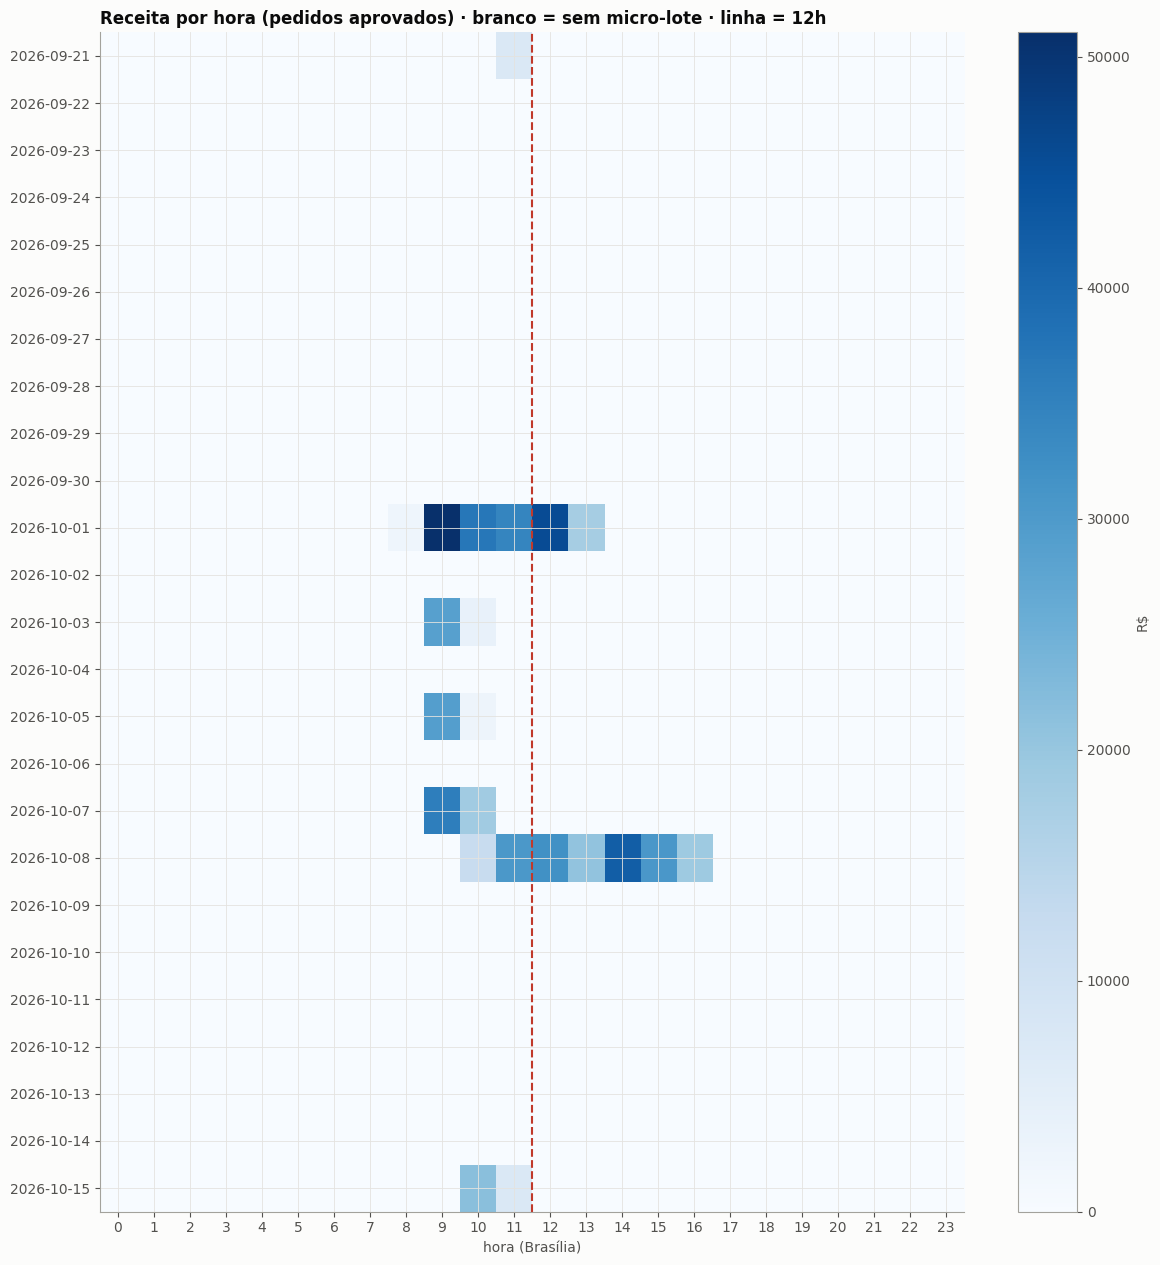

In [0]:
aprovados = pedidos[pedidos["aprovado"]].assign(hora_local=lambda d: d["local"].dt.floor("h"))
itens_aprov = itens[itens["aprovado"] & ~itens["item_invalido"]].assign(hora_local=lambda d: d["local"].dt.floor("h"))

inicio, fim = min(horas_com_lote).normalize(), max(horas_com_lote).normalize() + pd.Timedelta(hours=23)
grade = pd.DataFrame({"hora_local": pd.date_range(inicio, fim, freq="h")})
grade["tem_micro_lote"] = grade["hora_local"].isin(horas_com_lote)

por_hora = aprovados.groupby("hora_local").agg(receita=("valor_total", "sum"), pedidos=("id_pedido", "nunique"), frete=("valor_frete", "sum"))
itens_hora = itens_aprov.groupby("hora_local").agg(itens=("id_item_pedido", "count"), valor_bruto=("valor_bruto", "sum"),
                                                   desconto=("desconto_item", "sum"))
invalidos_hora = (itens[itens["aprovado"] & itens["item_invalido"]].assign(hora_local=lambda d: d["local"].dt.floor("h"))
                  .groupby("hora_local").size().rename("n_itens_invalidos"))
mix_hora = (pd.crosstab(itens_aprov["hora_local"], itens_aprov["grupo_mix"], values=itens_aprov["valor_bruto"], aggfunc="sum", normalize="index")
            .mul(100).reindex(columns=GRUPOS_MIX, fill_value=0).add_prefix("pct_valor_"))

features_hora = grade.set_index("hora_local").join(por_hora).join(itens_hora).join(invalidos_hora).join(mix_hora).reset_index()
contagens = ["receita", "pedidos", "frete", "itens", "valor_bruto", "desconto", "n_itens_invalidos"]
features_hora[contagens] = features_hora[contagens].fillna(0)                           # hora com micro-lote e sem venda = 0
features_hora["itens_por_pedido"] = features_hora["itens"] / features_hora["pedidos"].replace(0, np.nan)
features_hora["ticket_medio"] = features_hora["receita"] / features_hora["pedidos"].replace(0, np.nan)
features_hora["pct_desconto"] = 100 * features_hora["desconto"] / features_hora["valor_bruto"].replace(0, np.nan)
colunas_medidas = contagens + ["itens_por_pedido", "ticket_medio", "pct_desconto"] + [f"pct_valor_{g}" for g in GRUPOS_MIX]
features_hora.loc[~features_hora["tem_micro_lote"], colunas_medidas] = np.nan          # sem micro-lote = dado desconhecido

features_hora["data"] = features_hora["hora_local"].dt.date.astype(str)
features_hora["hora"] = features_hora["hora_local"].dt.hour
features_hora["dia_semana"] = features_hora["hora_local"].dt.dayofweek
features_hora["fim_de_semana"] = (features_hora["dia_semana"] >= 5).astype(int)
features_hora["periodo"] = np.select([features_hora["hora"] < HORA_PREVISAO, features_hora["hora"] < FIM_TARDE], ["manha", "tarde"], "noite")
for alvo in ["receita", "pedidos"]:
    for lag in LAGS_H:                                                                  # a grade é contínua: shift(n) = n horas antes
        features_hora[f"{alvo}_lag_{lag}h"] = features_hora[alvo].shift(lag)
    features_hora[f"{alvo}_media_{JANELA_MEDIA_H}h"] = features_hora[alvo].shift(1).rolling(JANELA_MEDIA_H, min_periods=JANELA_MEDIA_H).mean()

passos = features_hora["hora_local"].diff().dropna()
com_lote = features_hora[features_hora["tem_micro_lote"]]
mix_ok = (com_lote.loc[com_lote["itens"] > 0, [f"pct_valor_{g}" for g in GRUPOS_MIX]].sum(axis=1) - 100).abs() < 0.01
LAG24_CONHECIDO = int(com_lote["receita_lag_24h"].notna().sum())

# ------------------------------ validação ------------------------------
checar((passos == pd.Timedelta(hours=1)).all(), f"Grade contínua: {len(features_hora):,} horas ({features_hora['data'].nunique()} dias)", "Grade de horas com buraco")
checar(features_hora.loc[~features_hora["tem_micro_lote"], "receita"].isna().all(), "Horas sem micro-lote ficaram vazias (não zero)",
       "Hora sem micro-lote com valor")
checar(mix_ok.all(), "Mix por hora soma 100%", "Mix por hora não soma 100%", parar=False)
receita_horas_lote = aprovados.loc[aprovados["hora_local"].isin(horas_com_lote), "valor_total"].sum()
FORA_DA_GRADE_PCT = 100 * (1 - receita_horas_lote / aprovados["valor_total"].sum()) if len(aprovados) else 0.0
checar(abs(features_hora["receita"].sum() - receita_horas_lote) <= 0.01, "Receita da grade = receita dos pedidos aprovados nas horas com micro-lote",
       "Receita da grade diferente da dos pedidos aprovados")
print(f"Receita de pedidos em horas sem micro-lote (ex.: 8:50 que chega no lote das 9:00): {FORA_DA_GRADE_PCT:.1f}% · fica fora da grade")
checar(LAG24_CONHECIDO > 0, f"{LAG24_CONHECIDO} de {len(com_lote)} horas com micro-lote têm o lag de 24h conhecido",
       f"Nenhuma hora com o lag de 24h conhecido: o gerador nunca rodou em dois dias seguidos na mesma hora", parar=False)

# ------------------------------ resultado ------------------------------
display(features_hora[features_hora["tem_micro_lote"]].head(12))
dias = features_hora.pivot_table(index="data", columns="hora", values="receita", aggfunc="sum")
dias = dias.loc[dias.notna().any(axis=1)]
fig, eixo = plt.subplots(figsize=(12, 0.45 * len(dias) + 1.5))
imagem = eixo.imshow(dias.values, aspect="auto", cmap="Blues")
eixo.set_yticks(range(len(dias)), dias.index)
eixo.set_xticks(range(dias.shape[1]), dias.columns)
eixo.axvline(HORA_PREVISAO - 0.5, color="#C0392B", linestyle="--")
eixo.set_title("Receita por hora (pedidos aprovados) · branco = sem micro-lote · linha = 12h")
eixo.set_xlabel("hora (Brasília)")
plt.colorbar(imagem, ax=eixo, label="R$")
plt.tight_layout()
plt.show()

## Etapa 6 — Features do P1 por dia (manhã → tarde)
**Faz:** uma linha por dia com micro-lote. As features usam **só o que chegou até as 12h** (micro-lotes gerados antes das 12h com pedidos da manhã):
`receita_manha`, `pedidos_manha`, `itens_por_pedido_manha`, `pct_desconto_manha`, o mix `pct_valor_<grupo>_manha` e `horas_manha_com_lote`.
O **alvo** é a tarde (12h às 17:59): `alvo_receita_tarde` e `alvo_pedidos_tarde` (pedidos aprovados). Inclui a tarde do dia anterior (`receita_tarde_dia_anterior`)
e o calendário. `dia_completo` = as 6 horas da tarde com micro-lote e ao menos 3 horas da manhã (mesma regra do `12_ml_eda_itens`).
**Valida:** um registro por dia e quantos dias completos existem para treinar (⚠️ se nenhum).

In [0]:
manha_conhecida = lambda d: (d["local"].dt.hour < HORA_PREVISAO) & (d["janela_ref"] < d["local"].dt.normalize() + pd.Timedelta(hours=HORA_PREVISAO))
ped_dia = aprovados.assign(data=lambda d: d["local"].dt.date.astype(str), janela_ref=lambda d: d["janela"])
it_dia = itens_aprov.assign(data=lambda d: d["local"].dt.date.astype(str), janela_ref=lambda d: d["janela_pedido"])
ped_manha, it_manha = ped_dia[manha_conhecida(ped_dia)], it_dia[manha_conhecida(it_dia)]
ped_tarde = ped_dia[(ped_dia["local"].dt.hour >= HORA_PREVISAO) & (ped_dia["local"].dt.hour < FIM_TARDE)]

horas = pd.DataFrame({"hora_local": sorted(horas_com_lote)})
horas["data"], horas["hora"] = horas["hora_local"].dt.date.astype(str), horas["hora_local"].dt.hour
cobertura = horas.groupby("data").agg(horas_manha_com_lote=("hora", lambda h: int((h < HORA_PREVISAO).sum())),
                                      horas_tarde_com_lote=("hora", lambda h: int(((h >= HORA_PREVISAO) & (h < FIM_TARDE)).sum())))

manha = ped_manha.groupby("data").agg(receita_manha=("valor_total", "sum"), pedidos_manha=("id_pedido", "nunique"))
manha_itens = it_manha.groupby("data").agg(itens_manha=("id_item_pedido", "count"), bruto_manha=("valor_bruto", "sum"), desconto_manha=("desconto_item", "sum"))
mix_manha = (pd.crosstab(it_manha["data"], it_manha["grupo_mix"], values=it_manha["valor_bruto"], aggfunc="sum", normalize="index")
             .mul(100).reindex(columns=GRUPOS_MIX, fill_value=0).add_prefix("pct_valor_").add_suffix("_manha"))
tarde = ped_tarde.groupby("data").agg(alvo_receita_tarde=("valor_total", "sum"), alvo_pedidos_tarde=("id_pedido", "nunique"))

features_dia = cobertura.join(manha).join(manha_itens).join(mix_manha).join(tarde).reset_index()
features_dia[["receita_manha", "pedidos_manha", "itens_manha", "bruto_manha", "desconto_manha", "alvo_receita_tarde", "alvo_pedidos_tarde"]] = \
    features_dia[["receita_manha", "pedidos_manha", "itens_manha", "bruto_manha", "desconto_manha", "alvo_receita_tarde", "alvo_pedidos_tarde"]].fillna(0)
features_dia["itens_por_pedido_manha"] = features_dia["itens_manha"] / features_dia["pedidos_manha"].replace(0, np.nan)
features_dia["pct_desconto_manha"] = 100 * features_dia["desconto_manha"] / features_dia["bruto_manha"].replace(0, np.nan)
features_dia = features_dia.drop(columns=["bruto_manha", "desconto_manha"])
features_dia["dia_completo"] = (features_dia["horas_tarde_com_lote"] == FIM_TARDE - HORA_PREVISAO) & (features_dia["horas_manha_com_lote"] >= MIN_HORAS_MANHA)
datas = pd.to_datetime(features_dia["data"])
features_dia["dia_semana"] = datas.dt.dayofweek
features_dia["fim_de_semana"] = (features_dia["dia_semana"] >= 5).astype(int)
anterior = features_dia.set_index(datas)[["alvo_receita_tarde", "dia_completo"]]
anterior = anterior[anterior["dia_completo"]]["alvo_receita_tarde"]                  # só tarde completa vale como referência
features_dia["receita_tarde_dia_anterior"] = (datas - pd.Timedelta(days=1)).map(anterior)
DIAS_COMPLETOS = int(features_dia["dia_completo"].sum())

# ------------------------------ validação ------------------------------
checar(features_dia["data"].is_unique, f"{len(features_dia)} dias · um registro por dia", "Dia repetido nas features do P1")
checar(DIAS_COMPLETOS > 0, f"{DIAS_COMPLETOS} dias completos para treinar o P1",
       "Nenhum dia completo (6 horas da tarde + 3 da manhã): as features estão prontas, mas ainda não há linhas para treinar o P1", parar=False)

# ------------------------------ resultado ------------------------------
display(features_dia)

✅ 7 dias · um registro por dia
⚠️ Nenhum dia completo (6 horas da tarde + 3 da manhã): as features estão prontas, mas ainda não há linhas para treinar o P1


data,horas_manha_com_lote,horas_tarde_com_lote,receita_manha,pedidos_manha,itens_manha,pct_valor_racao_caes_manha,pct_valor_fraldas_manha,pct_valor_sabao_po_liquido_manha,pct_valor_refrigerantes_manha,pct_valor_desinfetantes_manha,pct_valor_sacos_de_lixo_manha,pct_valor_amaciantes_manha,pct_valor_esponjas_las_de_aco_manha,pct_valor_outras_manha,alvo_receita_tarde,alvo_pedidos_tarde,itens_por_pedido_manha,pct_desconto_manha,dia_completo,dia_semana,fim_de_semana,receita_tarde_dia_anterior
2026-09-21,1,0,7291.47,24,111,29.150237734357642,7.51528007143342,6.357547683271034,0.5455980220075612,22.964486891674838,2.1251708320635982,3.454700060814219,1.1975211219624498,26.689457582415244,0.0,0.0,4.625,2.521328225116405,false,0,0,null
2026-10-01,4,2,124557.88,449,2847,15.58620539797304,3.6762885113843145,3.9172206781109136,4.253550906907819,2.6590587642706645,2.2298655690105083,1.883115795471504,1.2698565513132776,64.52483782555795,63351.53,230.0,6.34075723830735,5.544088104229852,false,3,0,null
2026-10-03,2,0,32117.77,105,656,6.497498838664797,1.3084471975780156,0.9547548381339005,9.237334581244266,0.1919635603905748,0.7958864706165032,0.9256070407806004,0.33032263379382476,79.75818483879753,2491.74,13.0,6.247619047619048,7.841815847706048,false,5,1,null
2026-10-05,2,0,30318.54,112,830,4.635835039456315,0.0,1.220685038112424,6.266607473699137,1.031768025355351,1.1612140242845637,0.6702460493482749,0.24866607288334938,84.76497827686057,1439.82,8.0,7.410714285714286,5.85661275966821,false,0,0,null
2026-10-07,2,0,53675.909999999996,203,1420,8.198490448198893,3.081872207098016,2.6892631318184317,7.307256507794175,3.0471209394705143,2.885105365948119,2.1022772373091145,1.0553953000306169,69.63321886233213,1299.45,9.0,6.995073891625616,5.717403459251434,false,2,0,null
2026-10-08,2,6,42334.53,174,914,23.116720529359917,2.6809589167240375,12.773504816947234,1.42934193967086,3.0542339584913765,3.235598489798245,4.4662989094449,2.6967449977855633,46.54659744177786,144461.85,527.0,5.252873563218391,6.853549017974207,false,3,0,null
2026-10-15,2,0,28823.01,113,613,27.016042419448492,9.139666378354812,5.028131120916972,0.5619531609028728,3.60780749351617,2.755014172322954,3.1547202089612933,2.874588167655999,45.86207687792043,0.0,0.0,5.424778761061947,7.6537236527688455,false,3,0,null


## Etapa 7 — Gravação e conferência
**Faz:** grava as três tabelas em Delta com **overwrite** (são recalculadas do zero a cada execução, a partir de todo o `raw`), na subpasta da nossa tabela em `squad2/gold/`.
Com `GRAVAR = False`, só mostra o que gravaria. Com `REGISTRAR_CATALOGO = True`, grava também cópias no Unity Catalog
(`workspace.squad2.ml_features_*`), para consultar pelo nome em SQL — deixe `False` até combinar com o orientador.
**Valida:** relê cada tabela e confere o número de linhas e de colunas.

In [0]:
def para_spark(df):
    """pandas -> Spark: tipos anuláveis do pandas viram tipos simples."""
    saida = df.copy()
    for c in saida.columns:
        tipo = str(saida[c].dtype)
        if tipo in ("Int64", "Float64"):                    # tipos anuláveis do pandas: o Spark recebe float com NaN
            saida[c] = saida[c].astype("float64")
        elif tipo == "boolean":
            saida[c] = saida[c].fillna(False).astype(bool)
    return spark.createDataFrame(saida)


tabelas_ml = {"pedido": features_pedido.assign(id_pedido=features_pedido["id_pedido"].astype("int64")),
              "hora": features_hora, "dia": features_dia}
gravadas = []
for nome, df in tabelas_ml.items():
    if GRAVAR:
        escrever_delta(para_spark(df), DESTINOS[nome], "overwrite", opcoes={"overwriteSchema": "true"})
        relida = ler_delta(DESTINOS[nome])
        linhas, colunas = relida.count(), len(relida.columns)
        checar(linhas == len(df) and colunas == len(df.columns), f"{nome}: {linhas:,} linhas · {colunas} colunas gravadas",
               f"{nome}: gravou {linhas} linhas/{colunas} colunas, esperado {len(df)}/{len(df.columns)}")
    gravadas.append({"tabela": DESTINOS[nome].rsplit("/", 1)[-1], "linhas": len(df), "colunas": len(df.columns),
                     "gravada": "sim" if GRAVAR else "não (GRAVAR = False)"})

if GRAVAR and REGISTRAR_CATALOGO:
    for nome, df in tabelas_ml.items():
        nome_tabela = f"{CATALOGO_SCHEMA}.{DESTINOS[nome].rstrip('/').rsplit('/', 1)[-1]}"
        try:
            ler_delta(DESTINOS[nome]).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nome_tabela)
            checar(spark.table(nome_tabela).count() == len(df), f"Unity Catalog: {nome_tabela}", f"Unity Catalog: {nome_tabela} com linhas diferentes", parar=False)
        except Exception as erro:
            checar(False, "", f"Unity Catalog: não foi possível gravar {nome_tabela} ({type(erro).__name__})", parar=False)

# ------------------------------ resultado ------------------------------
display(pd.DataFrame(gravadas))

✅ pedido: 2,375 linhas · 35 colunas gravadas
✅ hora: 600 linhas · 76 colunas gravadas
✅ dia: 7 linhas · 23 colunas gravadas


tabela,linhas,colunas,gravada
ml_features_itens_pedido,2375,35,sim
ml_features_itens_hora,600,76,sim
ml_features_p1_dia,7,23,sim


## Preparação da análise
**Faz:** junta as 3 tabelas recém-criadas para a análise e calcula os números gerais (features, dias completos, lag de 24h).
**Valida:** que há features numéricas.

In [0]:
f_pedido = features_pedido.copy()
f_hora = features_hora.sort_values("hora_local").reset_index(drop=True)
f_dia = features_dia.sort_values("data").reset_index(drop=True)
horas_obs = f_hora[f_hora["tem_micro_lote"].astype(bool)].copy()                  # horas em que o gerador produziu micro-lote
NOME_GRUPO = {coluna_segura(c): c for c in ranking.index}
NOME_GRUPO["outras"] = "Outras"
COR_GRUPO = {g: CORES[i] for i, g in enumerate([g for g in GRUPOS_MIX if g != "outras"][:len(CORES)])}
COR_GRUPO["outras"] = CINZA
N_FEATURES = (len(f_pedido.drop(columns=["id_pedido"]).select_dtypes("number").columns)
              + len(f_hora.select_dtypes("number").columns) + len(f_dia.select_dtypes("number").columns))
DIAS_COMPLETOS = int(f_dia["dia_completo"].astype(bool).sum())
PCT_LAG24 = 100 * horas_obs["receita_lag_24h"].notna().mean() if len(horas_obs) else 0.0
ULTIMO_LOTE = max(horas_com_lote) if horas_com_lote else AGORA
DIAS_SEM_DADO = int((AGORA.normalize() - ULTIMO_LOTE.normalize()).days)

# ------------------------------ validação ------------------------------
checar(N_FEATURES > 0, f"{N_FEATURES} features numéricas · {len(f_pedido):,} pedidos · {len(f_hora):,} horas ({len(horas_obs)} com micro-lote) · {len(f_dia)} dias",
       "Nenhuma feature numérica")

✅ 121 features numéricas · 2,375 pedidos · 600 horas (23 com micro-lote) · 7 dias


## Etapa 8 — Codificação e normalização (tabelas prontas para o modelo)
**Faz:** o que o orientador definiu como engenharia de features: **transformar as colunas categóricas em numéricas e normalizá-las** para servirem de entrada ao modelo.

| Passo | Regra |
|---|---|
| Sim/não | vira **0/1** (`aprovado`, `tem_micro_lote`, `dia_completo`) |
| Categóricas | **one-hot**: uma coluna 0/1 por valor (`periodo`, `categoria_dominante`, `marca_dominante`), com os mais frequentes e o resto em `outras` |
| Fora do modelo | chaves (`id_pedido`, `data`, `hora_local`), a data do pedido (já há `hora` e `dia_semana`) e o texto `cesta_skus` (usado no P2) |
| Numéricas | **padronização** (z-score): `(valor − média) ÷ desvio`, ficando com média 0 e desvio 1 |
| Não normalizadas | colunas 0/1 e os **alvos** (`alvo_receita_tarde`, `alvo_pedidos_tarde`, e `receita`/`pedidos` na tabela por hora), que o modelo prevê na escala real |

Grava 3 tabelas **só com números** ao lado das atuais (que continuam legíveis): `ml_modelo_itens_pedido`, `ml_modelo_itens_hora`, `ml_modelo_p1_dia`,
e salva a média e o desvio de cada coluna em `metadata/` (`ml_normalizacao_itens.json`), para o modelo da próxima semana aplicar exatamente a mesma conta.
Vazios continuam vazios (o LightGBM aceita). *Obs.: o LightGBM não exige normalização (usa árvores), mas a padronização deixa as tabelas prontas para qualquer modelo.*
**Valida:** nenhuma coluna de texto sobra fora das chaves · colunas normalizadas com média 0 e desvio 1 · mesmo número de linhas · tabelas relidas.

✅ Nenhuma coluna de texto fora das chaves (4 categóricas → 28 colunas 0/1)
✅ 114 colunas normalizadas com média 0 e desvio 1
✅ Mesmo número de linhas das tabelas de features
✅ 3 tabelas para o modelo gravadas e relidas
✅ Média e desvio de cada coluna salvos em metadata/ml_normalizacao_itens.json


tabela,linhas,colunas,chaves,alvos_sem_normalizar,normalizadas,binarias_0_1
ml_modelo_itens_pedido,2375,55,1,0,28,26
ml_modelo_itens_hora,600,78,2,2,69,5
ml_modelo_p1_dia,7,23,1,2,17,3


tabela,coluna,tratamento,colunas_geradas
pedido,cesta_skus,removida · texto da cesta (usado no P2),0
pedido,categoria_dominante,one-hot · 108 valores → 11 colunas 0/1,11
pedido,marca_dominante,one-hot · 204 valores → 11 colunas 0/1,11
pedido,dt_pedido_local,removida · data do pedido (já há hora e dia_semana),0
pedido,aprovado,sim/não → 0/1,1
pedido,periodo,one-hot · 3 valores → 3 colunas 0/1,3
hora,tem_micro_lote,sim/não → 0/1,1
hora,periodo,one-hot · 3 valores → 3 colunas 0/1,3
dia,dia_completo,sim/não → 0/1,1


tabela,coluna,media,desvio,vazios_pct,observacao
pedido,n_itens,5.977263,4.476313,0.0,
pedido,n_skus,5.977263,4.476313,0.0,
pedido,quantidade_total,8.899368,8.289269,0.0,
pedido,valor_bruto,277.762493,414.462459,0.0,
pedido,desconto_total,16.573575,56.724478,0.0,
pedido,valor_liquido,261.188918,394.948003,0.0,
pedido,n_itens_invalidos,0.290526,0.572175,0.0,
pedido,preco_medio_item,38.751118,62.176194,0.0,
pedido,preco_max_item,94.368914,238.290127,0.0,
pedido,pct_itens_com_desconto,18.436978,20.202729,0.0,


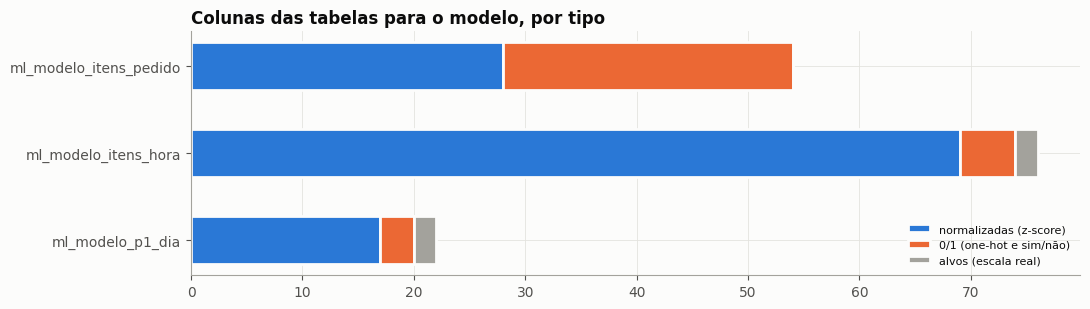

📌 Leitura
   • 4 colunas categóricas viraram 28 colunas 0/1 (one-hot); colunas sim/não viraram 0/1; nenhum texto sobrou fora das chaves.
   • 114 colunas numéricas padronizadas (média 0, desvio 1); 0/1 e alvos ficaram na escala original.
   • Exemplo: n_itens (pedido) — média 5,98 e desvio 4,48: um valor igual à média vira 0, e um desvio acima vira 1.
   • As tabelas legíveis (ml_features_*) continuam iguais; as tabelas ml_modelo_* são a entrada do modelo da próxima semana.


In [0]:
secao("2.0", "Codificação e normalização (Etapa 8)")
TOP_VALORES = 10                                    # one-hot: os valores mais frequentes de cada categórica; o resto vira "outras"
CHAVES = {"pedido": ["id_pedido"], "hora": ["data", "hora_local"], "dia": ["data"]}
ALVOS = {"pedido": [], "hora": ["receita", "pedidos"], "dia": ["alvo_receita_tarde", "alvo_pedidos_tarde"]}
FORA_DO_MODELO = {"cesta_skus": "texto da cesta (usado no P2)", "dt_pedido_local": "data do pedido (já há hora e dia_semana)"}
DESTINOS_MODELO = {"pedido": caminho_gold("ml_modelo_itens_pedido"), "hora": caminho_gold("ml_modelo_itens_hora"),
                   "dia": caminho_gold("ml_modelo_p1_dia")}


def codificar(df, nome):
    """Sim/não → 0/1; categóricas → one-hot (TOP_VALORES + 'outras'); remove o que não é feature. Devolve a tabela e o registro do que foi feito."""
    saida, feito = df.copy(), []
    for coluna in [c for c in df.columns if c not in CHAVES[nome]]:
        serie = saida[coluna]
        if coluna in FORA_DO_MODELO:
            saida = saida.drop(columns=coluna)
            feito.append({"tabela": nome, "coluna": coluna, "tratamento": f"removida · {FORA_DO_MODELO[coluna]}", "colunas_geradas": 0})
        elif serie.dtype == bool or str(serie.dtype) == "boolean":
            saida[coluna] = serie.fillna(False).astype(int)
            feito.append({"tabela": nome, "coluna": coluna, "tratamento": "sim/não → 0/1", "colunas_geradas": 1})
        elif pd.api.types.is_datetime64_any_dtype(serie):
            saida = saida.drop(columns=coluna)
            feito.append({"tabela": nome, "coluna": coluna, "tratamento": "removida · data (já há hora e dia_semana)", "colunas_geradas": 0})
        elif not pd.api.types.is_numeric_dtype(serie):
            principais = serie.value_counts().index[:TOP_VALORES]
            rotulos = serie.where(serie.isin(principais), "outras").fillna("outras").map(coluna_segura)
            dummies = pd.get_dummies(rotulos, prefix=coluna, dtype=int)
            saida = pd.concat([saida.drop(columns=coluna), dummies], axis=1)
            feito.append({"tabela": nome, "coluna": coluna, "tratamento": f"one-hot · {serie.nunique()} valores → {dummies.shape[1]} colunas 0/1",
                          "colunas_geradas": dummies.shape[1]})
    return saida, feito


def normalizar(df, nome):
    """Padroniza (z-score) as numéricas que não são chave, alvo nem 0/1. Devolve a tabela e os parâmetros de cada coluna."""
    saida, parametros = df.copy(), []
    for coluna in [c for c in df.columns if c not in CHAVES[nome] + ALVOS[nome]]:
        serie = pd.to_numeric(saida[coluna], errors="coerce").astype(float)
        if set(serie.dropna().unique()) <= {0.0, 1.0}:
            continue                                    # 0/1 (one-hot e sim/não) fica como está
        media, desvio = serie.mean(), serie.std(ddof=0)
        constante = not desvio or np.isnan(desvio)
        saida[coluna] = 0.0 if constante else (serie - media) / desvio
        parametros.append({"tabela": nome, "coluna": coluna, "media": round(float(media), 6) if not np.isnan(media) else None,
                           "desvio": round(float(desvio), 6) if not constante else None, "vazios_pct": round(100 * serie.isna().mean(), 1),
                           "observacao": "constante → 0" if constante else ""})
    return saida, parametros


modelo, codificacao, normalizacao = {}, [], []
for nome, df in [("pedido", features_pedido), ("hora", features_hora), ("dia", features_dia)]:
    codificada, feito = codificar(df, nome)
    normalizada, parametros = normalizar(codificada, nome)
    modelo[nome] = normalizada
    codificacao += feito
    normalizacao += parametros
codificacao, normalizacao = pd.DataFrame(codificacao), pd.DataFrame(normalizacao)

texto_sobrando = {n: [c for c in df.columns if c not in CHAVES[n] and not pd.api.types.is_numeric_dtype(df[c])] for n, df in modelo.items()}
conferencia = []
for _, p in normalizacao[normalizacao["desvio"].notna()].iterrows():
    serie = modelo[p["tabela"]][p["coluna"]].dropna()
    conferencia.append(abs(serie.mean()) < 1e-6 and abs(serie.std(ddof=0) - 1) < 1e-6)

gravadas_modelo = []
if GRAVAR:
    for nome, df in modelo.items():
        escrever_delta(para_spark(df), DESTINOS_MODELO[nome], "overwrite", opcoes={"overwriteSchema": "true"})
        relida = ler_delta(DESTINOS_MODELO[nome])
        gravadas_modelo.append(relida.count() == len(df) and len(relida.columns) == df.shape[1])
PARAMETROS_SALVOS = False
if GRAVAR and "escrever_metadata" in globals():
    escrever_metadata("ml_normalizacao_itens", {"gerado_em": f"{AGORA:%m/%d/%Y %H:%M:%S}", "metodo": "z-score (média 0, desvio 1)",
                                                "top_valores_one_hot": TOP_VALORES, "alvos_sem_normalizar": ALVOS,
                                                "parametros": normalizacao.where(normalizacao.notna(), None).to_dict("records")})
    PARAMETROS_SALVOS = True

resumo_modelo = pd.DataFrame([{"tabela": DESTINOS_MODELO[n].rstrip("/").rsplit("/", 1)[-1], "linhas": len(df), "colunas": df.shape[1],
                               "chaves": len(CHAVES[n]), "alvos_sem_normalizar": len([a for a in ALVOS[n] if a in df.columns]),
                               "normalizadas": int((normalizacao["tabela"] == n).sum()),
                               "binarias_0_1": df.shape[1] - len(CHAVES[n]) - len([a for a in ALVOS[n] if a in df.columns]) - int((normalizacao["tabela"] == n).sum())}
                              for n, df in modelo.items()])
N_CATEGORICAS = int(codificacao["tratamento"].str.startswith("one-hot").sum()) if len(codificacao) else 0
N_ONE_HOT = int(codificacao.loc[codificacao["tratamento"].str.startswith("one-hot"), "colunas_geradas"].sum()) if len(codificacao) else 0
N_NORMALIZADAS = len(normalizacao)
N_CONSTANTES = int(normalizacao["desvio"].isna().sum()) if len(normalizacao) else 0
CODIFICACAO_OK = not any(texto_sobrando.values())
NORMALIZACAO_OK = all(conferencia) and len(conferencia) > 0

# ------------------------------ validação ------------------------------
checar(CODIFICACAO_OK, f"Nenhuma coluna de texto fora das chaves ({N_CATEGORICAS} categóricas → {N_ONE_HOT} colunas 0/1)",
       f"Ainda há colunas de texto: {texto_sobrando}")
checar(NORMALIZACAO_OK, f"{len(conferencia)} colunas normalizadas com média 0 e desvio 1", "Há colunas normalizadas fora de média 0 e desvio 1", parar=False)
checar(all(len(modelo[n]) == len(df) for n, df in [("pedido", features_pedido), ("hora", features_hora), ("dia", features_dia)]),
       "Mesmo número de linhas das tabelas de features", "Número de linhas mudou na codificação")
if GRAVAR:
    checar(all(gravadas_modelo), f"{len(gravadas_modelo)} tabelas para o modelo gravadas e relidas", "Tabelas para o modelo com linhas ou colunas diferentes")
    checar(PARAMETROS_SALVOS, "Média e desvio de cada coluna salvos em metadata/ml_normalizacao_itens.json",
           "Parâmetros da normalização não salvos (00_setup_config sem escrever_metadata)", parar=False)

# ------------------------------ resultado ------------------------------
exibir(resumo_modelo, "Tabelas prontas para o modelo")
exibir(codificacao, "Como cada coluna não numérica foi tratada", linhas=40)
exibir(normalizacao.head(15), "Parâmetros da normalização (primeiras colunas)", linhas=15)
fig, eixo = plt.subplots(figsize=(11, 3.2))
partes = [("normalizadas", "normalizadas (z-score)", CORES[0]), ("binarias_0_1", "0/1 (one-hot e sim/não)", CORES[1]),
          ("alvos_sem_normalizar", "alvos (escala real)", CINZA)]
esquerda = np.zeros(len(resumo_modelo))
for coluna, rotulo, cor in partes:
    eixo.barh(resumo_modelo["tabela"], resumo_modelo[coluna], left=esquerda, color=cor, label=rotulo, height=0.55, edgecolor=FUNDO, linewidth=2)
    esquerda += resumo_modelo[coluna].values
eixo.invert_yaxis()
eixo.legend(fontsize=8, loc="lower right")
eixo.set_title("Colunas das tabelas para o modelo, por tipo")
plt.tight_layout()
mostrar()
exemplo = normalizacao[normalizacao["desvio"].notna()].iloc[0] if (normalizacao["desvio"].notna()).any() else None
leitura(f"{N_CATEGORICAS} colunas categóricas viraram {N_ONE_HOT} colunas 0/1 (one-hot); colunas sim/não viraram 0/1; nenhum texto sobrou fora das chaves.",
        f"{N_NORMALIZADAS} colunas numéricas padronizadas (média 0, desvio 1)" + (f", das quais {N_CONSTANTES} constantes viraram 0" if N_CONSTANTES else "") + "; 0/1 e alvos ficaram na escala original.",
        (f"Exemplo: {exemplo['coluna']} ({exemplo['tabela']}) — média {br(exemplo['media'], 2)} e desvio {br(exemplo['desvio'], 2)}: "
         f"um valor igual à média vira 0, e um desvio acima vira 1." if exemplo is not None else "Nenhuma coluna com variação para normalizar."),
        "As tabelas legíveis (ml_features_*) continuam iguais; as tabelas ml_modelo_* são a entrada do modelo da próxima semana.")

---
# Análise das features

## 2.1 Do dado à feature
As Etapas 1 a 7 acima transformam os itens em **três tabelas de colunas numéricas**, gravadas em Delta (`overwrite`, recalculadas do `raw` a cada execução):

```text
raw (itens + pedidos + produtos + categorias) + Silver (pedidos aprovados)
        │
        ▼
itens enriquecidos: valor_bruto, desconto_item, valor_liquido, categoria, hora, item_invalido
        │
        ├──▶ ml_features_itens_pedido   1 linha por pedido      → perfil da cesta (P1 agregado, P3) e cesta de SKUs (P2)
        ├──▶ ml_features_itens_hora     1 linha por data + hora → volume, receita, mix, lags e calendário (P1)
        └──▶ ml_features_p1_dia         1 linha por dia         → manhã conhecida até 12h + alvo da tarde (P1)
```

**Regras:** receita = Σ `valor_total` dos pedidos **aprovados** · mix e médias só com itens válidos · hora **sem micro-lote = vazio** (desconhecido), hora com micro-lote e sem pedido = 0 ·
manhã do P1 = pedidos até 11:59 que chegaram em micro-lote gerado antes das 12h · lags de 1h a 24h (24h = baseline "mesma hora do dia anterior").
**O que observar:** abaixo, o tamanho de cada tabela e um **exemplo real** de pedido antes (linhas de itens) e depois (uma linha de features).

In [0]:
secao("2.1", "Do dado à feature")
visao = pd.DataFrame([{"tabela": nome, "uma_linha_por": por, "linhas": len(df), "colunas": df.shape[1],
                       "colunas_numericas": len(df.drop(columns=[c for c in ["id_pedido"] if c in df]).select_dtypes("number").columns),
                       "destino": DESTINOS[chave].split("@", 1)[-1].split("/", 1)[-1], "uso": uso}
                      for nome, chave, por, df, uso in [
                          ("ml_features_itens_pedido", "pedido", "pedido", f_pedido, "P1 (agregado), P3 · cesta para o P2"),
                          ("ml_features_itens_hora", "hora", "data + hora", f_hora, "P1"),
                          ("ml_features_p1_dia", "dia", "dia", f_dia, "P1 (manhã → tarde)")]])
exibir(visao, "Tabelas de features")

candidatos = f_pedido[(f_pedido["n_categorias"] >= 3) & (f_pedido["n_itens_invalidos"] == 0) & f_pedido["aprovado"].astype(bool)]
candidatos = candidatos if len(candidatos) else f_pedido
EXEMPLO = candidatos.sort_values("n_itens").iloc[len(candidatos) // 2]["id_pedido"]
antes = itens.loc[itens["id_pedido"] == EXEMPLO, ["sku", "categoria", "quantidade", "preco_unitario", "desconto_aplicado",
                                                    "valor_bruto", "desconto_item", "valor_liquido"]]
print(f"ANTES · pedido {EXEMPLO}: {len(antes)} linhas na tabela de itens")
display(antes.round(2))
depois = f_pedido[f_pedido["id_pedido"] == EXEMPLO].drop(columns=["cesta_skus"]).round(2).T.reset_index()
depois.columns = ["feature", "valor"]
depois["valor"] = depois["valor"].astype(str)
print(f"DEPOIS · o mesmo pedido em ml_features_itens_pedido: 1 linha com {len(depois)} colunas")
display(depois)
leitura(f"{N_FEATURES} colunas numéricas no total: {', '.join(f'{v} em {t}' for t, v in zip(visao['tabela'], visao['colunas_numericas']))}.",
        f"Exemplo: {len(antes)} itens do pedido {EXEMPLO} viram 1 linha; a soma valor_liquido {reais(antes['valor_liquido'].sum())} = valor_total do pedido.")

tabela,uma_linha_por,linhas,colunas,colunas_numericas,destino,uso
ml_features_itens_pedido,pedido,2375,35,28,gold/ecommerce_pedidos/ml_features_itens_pedido,"P1 (agregado), P3 · cesta para o P2"
ml_features_itens_hora,data + hora,600,76,72,gold/ecommerce_pedidos/ml_features_itens_hora,P1
ml_features_p1_dia,dia,7,23,21,gold/ecommerce_pedidos/ml_features_p1_dia,P1 (manhã → tarde)


ANTES · pedido 1790868242: 5 linhas na tabela de itens


sku,categoria,quantidade,preco_unitario,desconto_aplicado,valor_bruto,desconto_item,valor_liquido
sabonetesbarraliquido-dove-6un-glicerina,"Sabonetes (Barra, Líquido)",1,18.19,0.0,18.19,0.0,18.19
shampoos-lorealelseve-1l-hidratante,Shampoos,1,30.49,0.0,30.49,0.0,30.49
shampoos-headshoulders-02l-anticaspa,Shampoos,1,11.61,0.0,11.61,0.0,11.61
papelhigienico-scott-4un-folhasimples,Papel Higiênico,2,11.18,0.0,22.36,0.0,22.36
cremedental-sorriso-009kg-total12,Creme Dental,1,12.46,0.0,12.46,0.0,12.46


DEPOIS · o mesmo pedido em ml_features_itens_pedido: 1 linha com 34 colunas


feature,valor
id_pedido,1790868242
n_itens,5.0
n_skus,5.0
quantidade_total,6.0
valor_bruto,95.11
desconto_total,0.0
valor_liquido,95.11
n_itens_invalidos,0.0
preco_medio_item,16.79
preco_max_item,30.49


📌 Leitura
   • 121 colunas numéricas no total: 28 em ml_features_itens_pedido, 72 em ml_features_itens_hora, 21 em ml_features_p1_dia.
   • Exemplo: 5 itens do pedido 1790868242 viram 1 linha; a soma valor_liquido R$ 95,11 = valor_total do pedido.


## 2.2 Dicionário de features
Cada coluna numérica, a tabela, **como é calculada** e um resumo dos valores desta execução (vazios, mínimo, média, máximo).
Vazios nas tabelas por hora e por dia são esperados: correspondem a horas **sem micro-lote** ou a lags sem a hora anterior.

In [0]:
secao("2.2", "Dicionário de features")
DESCRICAO = {
    "n_itens": "nº de itens (linhas) do pedido", "n_skus": "nº de produtos diferentes no pedido", "quantidade_total": "Σ quantidade",
    "valor_bruto": "Σ quantidade × preço", "desconto_total": "Σ quantidade × desconto", "valor_liquido": "bruto − desconto (= valor_total)",
    "n_itens_invalidos": "itens com quantidade ≤ 0, preço ≤ 0 ou desconto < 0", "preco_medio_item": "média do preço unitário (itens válidos)",
    "preco_max_item": "maior preço unitário (itens válidos)", "pct_itens_com_desconto": "% dos itens válidos com desconto",
    "n_categorias": "nº de categorias distintas", "pct_desconto": "desconto ÷ valor bruto × 100", "valor_total": "valor do pedido (fonte)",
    "valor_frete": "frete do pedido (fonte, fora do valor_total)", "hora": "hora (Brasília, 0–23)", "dia_semana": "0 = segunda … 6 = domingo",
    "fim_de_semana": "1 = sábado ou domingo", "receita": "Σ valor_total dos pedidos aprovados na hora", "pedidos": "nº de pedidos aprovados",
    "frete": "Σ frete dos pedidos aprovados", "itens": "nº de itens válidos", "desconto": "Σ desconto dos itens válidos",
    "itens_por_pedido": "itens ÷ pedidos", "ticket_medio": "receita ÷ pedidos",
    "horas_manha_com_lote": "horas da manhã com micro-lote", "horas_tarde_com_lote": "horas da tarde com micro-lote",
    "receita_manha": "receita da manhã conhecida até 12h", "pedidos_manha": "pedidos da manhã conhecidos até 12h",
    "itens_manha": "itens válidos da manhã", "itens_por_pedido_manha": "itens ÷ pedidos da manhã", "pct_desconto_manha": "% de desconto da manhã",
    "alvo_receita_tarde": "🎯 ALVO · receita 12h–17:59 (aprovados)", "alvo_pedidos_tarde": "🎯 ALVO · nº de pedidos 12h–17:59",
    "receita_tarde_dia_anterior": "receita da tarde do dia anterior (se completo)",
    "valor_medio_item": "valor_liquido ÷ n_itens", "n_marcas": "nº de marcas distintas (itens válidos)",
    "pct_itens_por_peso": "% dos itens válidos vendidos por peso"}


def descrever(coluna):
    if coluna in DESCRICAO:
        return DESCRICAO[coluna]
    if m := re.fullmatch(r"pct_valor_(.+?)(_manha)?", coluna):
        return f"% do valor bruto em {NOME_GRUPO.get(m.group(1), m.group(1))}" + (" (manhã até 12h)" if m.group(2) else "")
    if m := re.fullmatch(r"(receita|pedidos)_lag_(\d+)h", coluna):
        return f"{m.group(1)} de {m.group(2)} h antes" + (" · baseline: mesma hora do dia anterior" if m.group(2) == "24" else "")
    if m := re.fullmatch(r"(receita|pedidos)_media_(\d+)h", coluna):
        return f"média de {m.group(1)} nas {m.group(2)} h anteriores"
    return "—"


linhas = []
for tabela, df in [("pedido", f_pedido.drop(columns=["id_pedido"])), ("hora", f_hora), ("dia", f_dia)]:
    for c in df.select_dtypes("number").columns:
        linhas.append({"tabela": tabela, "feature": c, "como_calcular": descrever(c), "vazios_pct": round(100 * df[c].isna().mean(), 1),
                       "minimo": round(df[c].min(), 2), "media": round(df[c].mean(), 2), "maximo": round(df[c].max(), 2)})
dicionario = pd.DataFrame(linhas)
exibir(dicionario, "Dicionário de features", linhas=200)
contagem = dicionario.groupby("tabela").size()
VAZIOS_PEDIDO = int((dicionario.loc[dicionario["tabela"] == "pedido", "vazios_pct"] > 0).sum())
leitura(f"{len(dicionario)} features: {contagem.get('pedido', 0)} por pedido, {contagem.get('hora', 0)} por hora e {contagem.get('dia', 0)} por dia.",
        f"{(dicionario['como_calcular'] == '—').sum()} features sem descrição." if (dicionario['como_calcular'] == '—').any() else "Todas as features têm descrição.",
        f"Por pedido, {VAZIOS_PEDIDO} features com vazio; por hora, os vazios vêm das {len(f_hora) - len(horas_obs)} horas sem micro-lote.")

tabela,feature,como_calcular,vazios_pct,minimo,media,maximo
pedido,n_itens,nº de itens (linhas) do pedido,0.0,1.0,5.98,30.0
pedido,n_skus,nº de produtos diferentes no pedido,0.0,1.0,5.98,30.0
pedido,quantidade_total,Σ quantidade,0.0,0.0,8.9,65.0
pedido,valor_bruto,Σ quantidade × preço,0.0,-200.34,277.76,7496.39
pedido,desconto_total,Σ quantidade × desconto,0.0,-62.57,16.57,1346.8
pedido,valor_liquido,bruto − desconto (= valor_total),0.0,-200.34,261.19,6767.39
pedido,n_itens_invalidos,"itens com quantidade ≤ 0, preço ≤ 0 ou desconto < 0",0.0,0.0,0.29,4.0
pedido,preco_medio_item,média do preço unitário (itens válidos),0.0,0.0,38.75,1798.08
pedido,preco_max_item,maior preço unitário (itens válidos),0.0,0.0,94.37,5292.0
pedido,pct_itens_com_desconto,% dos itens válidos com desconto,0.0,0.0,18.44,100.0


📌 Leitura
   • 121 features: 28 por pedido, 72 por hora e 21 por dia.
   • Todas as features têm descrição.
   • Por pedido, 0 features com vazio; por hora, os vazios vêm das 577 horas sem micro-lote.


## 2.3 Features por pedido
**O que observar:** a distribuição das principais features, quais andam juntas (correlação) e se o pedido da manhã é diferente do da tarde.

feature,count,mean,std,min,25%,50%,75%,95%,max
n_itens,2375.0,5.98,4.48,1.0,3.0,5.0,7.0,15.0,30.0
n_skus,2375.0,5.98,4.48,1.0,3.0,5.0,7.0,15.0,30.0
quantidade_total,2375.0,8.9,8.29,0.0,4.0,7.0,10.0,23.0,65.0
valor_bruto,2375.0,277.76,414.55,-200.34,100.42,177.62,309.54,794.97,7496.39
desconto_total,2375.0,16.57,56.74,-62.57,0.0,1.78,11.81,71.39,1346.8
valor_liquido,2375.0,261.19,395.03,-200.34,92.05,166.19,288.81,757.85,6767.39
pct_desconto,2375.0,6.13,13.56,-54.86,0.0,0.96,5.67,31.88,124.85
preco_medio_item,2375.0,38.75,62.19,0.0,18.04,21.74,34.4,122.75,1798.08
preco_max_item,2375.0,94.37,238.34,0.0,27.76,34.11,67.82,299.99,5292.0
valor_medio_item,2375.0,49.49,84.74,-66.78,21.19,29.15,45.96,152.45,1803.91


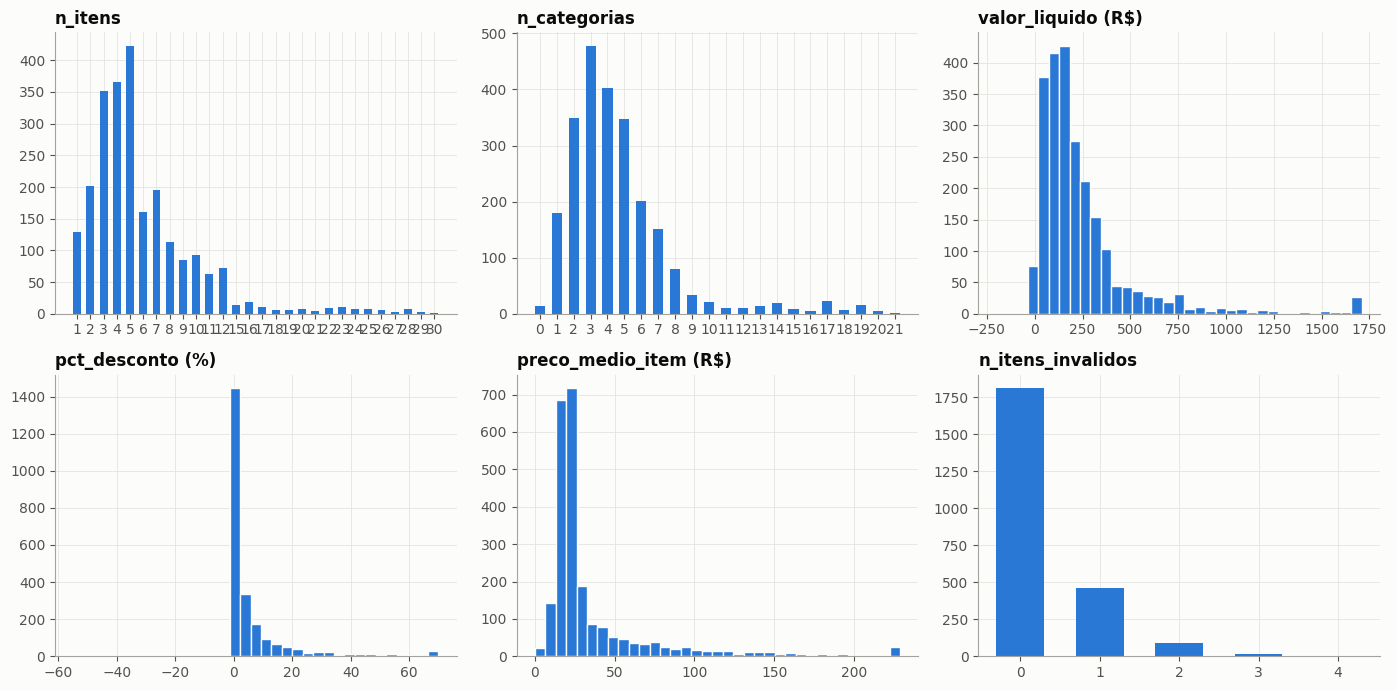

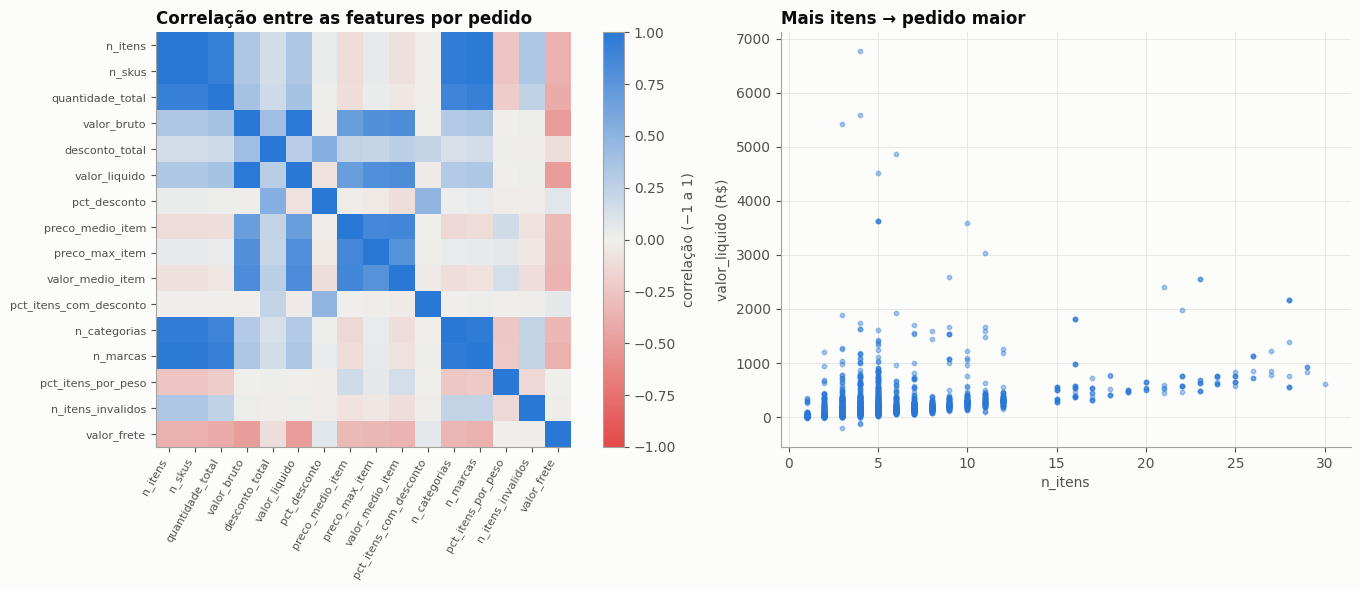

feature_a,feature_b,correlacao
n_itens,n_skus,1.0
valor_bruto,valor_liquido,0.991
n_itens,n_marcas,0.977
n_skus,n_marcas,0.977
n_categorias,n_marcas,0.968
n_itens,n_categorias,0.955
n_skus,n_categorias,0.955
n_skus,quantidade_total,0.927


feature (média por pedido),manha,tarde,diferenca_pct
n_itens,6.48,5.42,-16.38
n_skus,6.48,5.42,-16.38
quantidade_total,9.98,7.6,-23.91
valor_bruto,284.65,288.77,1.45
desconto_total,16.79,17.02,1.35
valor_liquido,267.86,271.75,1.45
pct_desconto,6.14,5.42,-11.77
preco_medio_item,34.53,47.59,37.82
preco_max_item,89.29,109.86,23.03
valor_medio_item,45.75,59.3,29.61


📌 Leitura
   • Pedido mediano: 5 itens, 4 categorias, R$ 166,19.
   • Feature mais ligada ao valor do pedido: valor_medio_item (correlação 0,83) — pista forte para o P3.
   • Par mais redundante: n_itens × n_skus (1,00): no modelo, um dos dois pode sair.
   • Manhã × tarde: a maior diferença está em preco_medio_item (37,8% à tarde).


In [0]:
secao("2.3", "Features por pedido")
FEATS_PEDIDO = [c for c in ["n_itens", "n_skus", "quantidade_total", "valor_bruto", "desconto_total", "valor_liquido", "pct_desconto",
                            "preco_medio_item", "preco_max_item", "valor_medio_item", "pct_itens_com_desconto", "n_categorias", "n_marcas",
                            "pct_itens_por_peso", "n_itens_invalidos", "valor_frete"]
                if c in f_pedido.columns]
display(f_pedido[FEATS_PEDIDO].describe(percentiles=[.25, .5, .75, .95]).T.round(2).reset_index(names="feature"))

fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for eixo, (coluna, titulo) in zip(eixos.flat, [("n_itens", "n_itens"), ("n_categorias", "n_categorias"), ("valor_liquido", "valor_liquido (R$)"),
                                               ("pct_desconto", "pct_desconto (%)"), ("preco_medio_item", "preco_medio_item (R$)"),
                                               ("n_itens_invalidos", "n_itens_invalidos")]):
    serie = f_pedido[coluna].dropna()
    if serie.nunique() <= 30:
        contagem = serie.value_counts().sort_index()
        eixo.bar(contagem.index.astype(int).astype(str) if (contagem.index % 1 == 0).all() else contagem.index.astype(str), contagem.values, color=CORES[0], width=0.6)
    else:
        eixo.hist(serie.clip(upper=serie.quantile(0.99)), bins=35, color=CORES[0], edgecolor=FUNDO)
    eixo.set_title(titulo)
plt.tight_layout()
mostrar()

correlacao = f_pedido[FEATS_PEDIDO].corr()
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.15, 1]})
imagem = eixo1.imshow(correlacao.values, cmap=DIVERGENTE, vmin=-1, vmax=1)
eixo1.set_xticks(range(len(FEATS_PEDIDO)), FEATS_PEDIDO, rotation=60, ha="right", fontsize=8)
eixo1.set_yticks(range(len(FEATS_PEDIDO)), FEATS_PEDIDO, fontsize=8)
eixo1.grid(False)
eixo1.set_title("Correlação entre as features por pedido")
plt.colorbar(imagem, ax=eixo1, fraction=0.04, label="correlação (−1 a 1)")
eixo2.scatter(f_pedido["n_itens"], f_pedido["valor_liquido"], s=10, alpha=0.4, color=CORES[0])
eixo2.set_xlabel("n_itens")
eixo2.set_ylabel("valor_liquido (R$)")
eixo2.set_title("Mais itens → pedido maior")
plt.tight_layout()
mostrar()

pares = (correlacao.where(np.triu(np.ones(correlacao.shape, dtype=bool), k=1)).stack().rename("correlacao").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pares = pares.reindex(pares["correlacao"].abs().sort_values(ascending=False).index).head(8).round(3)
exibir(pares, "Pares de features mais correlacionados")

ap = f_pedido[f_pedido["aprovado"].astype(bool) & f_pedido["periodo"].isin(["manha", "tarde"])]
perfil_periodo = ap.groupby("periodo")[FEATS_PEDIDO].mean().T
if {"manha", "tarde"} <= set(perfil_periodo.columns):
    perfil_periodo["diferenca_pct"] = 100 * (perfil_periodo["tarde"] / perfil_periodo["manha"].replace(0, np.nan) - 1)
    exibir(perfil_periodo.round(2).reset_index(names="feature (média por pedido)"), "Pedido da manhã × da tarde")
corr_valor = correlacao["valor_liquido"].drop(["valor_liquido", "valor_bruto"], errors="ignore").sort_values(key=abs, ascending=False)
frases = [f"Pedido mediano: {br(f_pedido['n_itens'].median())} itens, {br(f_pedido['n_categorias'].median())} categorias, {reais(f_pedido['valor_liquido'].median())}.",
          f"Feature mais ligada ao valor do pedido: {corr_valor.index[0]} (correlação {br(corr_valor.iloc[0], 2)}) — pista forte para o P3.",
          f"Par mais redundante: {pares.iloc[0]['feature_a']} × {pares.iloc[0]['feature_b']} ({br(pares.iloc[0]['correlacao'], 2)}): no modelo, um dos dois pode sair."]
if "diferenca_pct" in perfil_periodo:
    muda = perfil_periodo["diferenca_pct"].abs().idxmax()
    frases.append(f"Manhã × tarde: a maior diferença está em {muda} ({br(perfil_periodo.loc[muda, 'diferenca_pct'], 1)}% à tarde).")
leitura(*frases)

## 2.4 Features por hora
A grade tem **todas as horas** do primeiro ao último dia com dados. Só as horas com micro-lote têm valores; nelas calculamos receita, pedidos, ticket, mix e os **lags**.
**O que observar:** onde há dado (mapa), quanto dos lags é calculável e como receita, lag de 1h e média móvel se comportam num dia real.

data,hora,receita,pedidos,ticket_medio,itens_por_pedido,pct_desconto,receita_lag_1h,receita_lag_2h,receita_lag_24h,receita_media_3h
2026-09-21,11,7291.47,24.0,303.81,4.62,2.52,null,null,null,null
2026-10-01,8,2299.37,12.0,191.61,7.75,5.21,null,null,null,null
2026-10-01,9,51055.72,156.0,327.28,8.65,5.21,2299.37,null,null,null
2026-10-01,10,37011.99,143.0,258.83,4.95,6.07,51055.72,2299.37,null,null
2026-10-01,11,34207.7,139.0,246.1,5.02,5.49,37011.99,51055.72,null,30122.36
2026-10-01,12,45498.76,156.0,291.66,5.29,5.45,34207.7,37011.99,null,40758.47
2026-10-01,13,17852.77,74.0,241.25,5.23,4.8,45498.76,34207.7,null,38906.15
2026-10-03,9,28718.73,96.0,299.15,6.5,7.83,null,null,null,null
2026-10-03,10,3718.16,12.0,309.85,3.83,7.75,28718.73,null,null,null
2026-10-05,9,28968.07,108.0,268.22,7.53,5.92,null,null,null,null


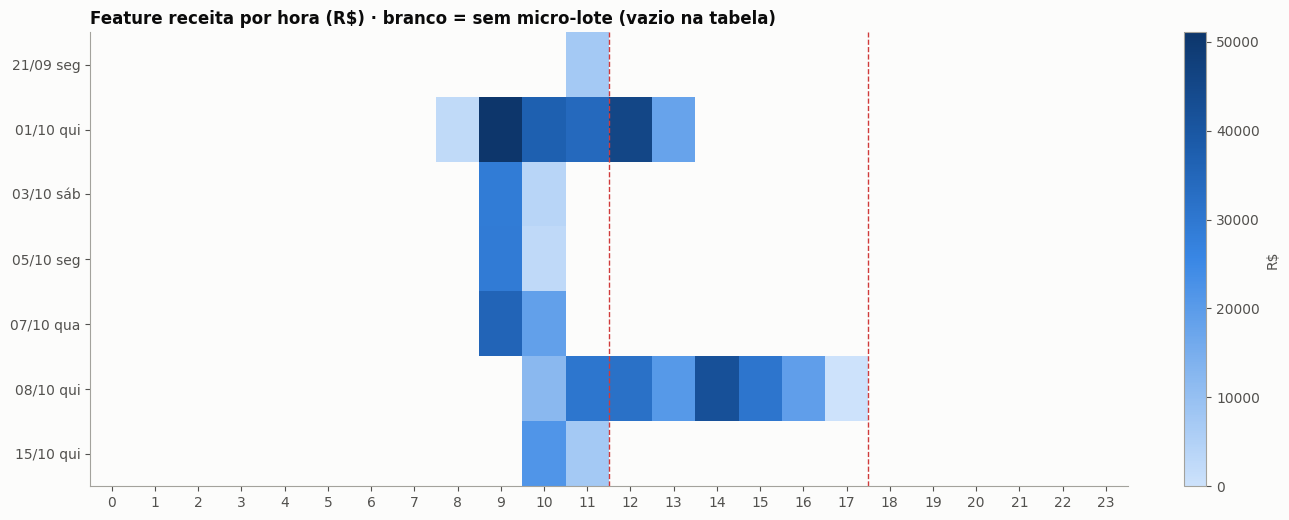

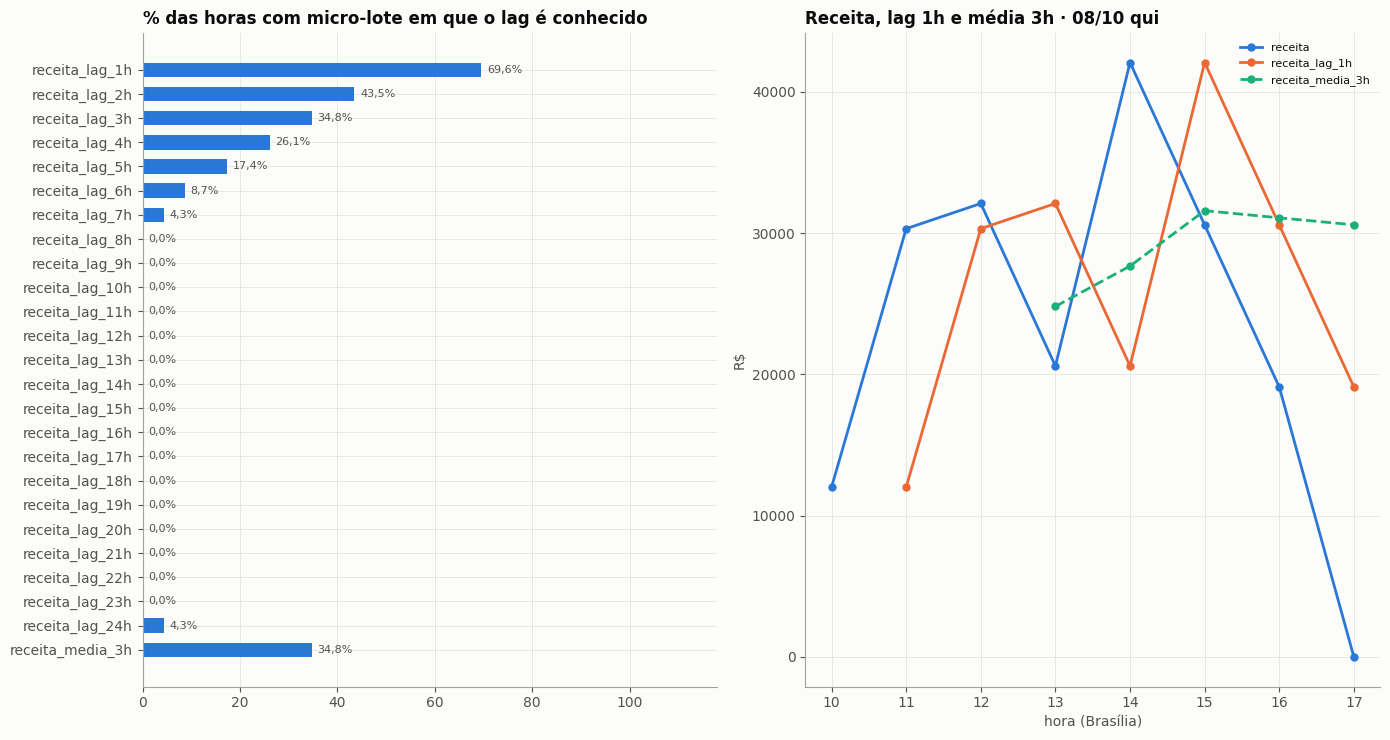

📌 Leitura
   • 23 horas com micro-lote de 600 na grade (3,8%).
   • Receita média por hora observada: R$ 22.997,29 (84,7 pedidos).
   • Lag de 1h conhecido em 69,6% das horas; lag de 24h (baseline) em só 4,3%.
   • Onde existe, a receita de uma hora se correlaciona -0,07 com a da hora anterior (n = 16).


In [0]:
secao("2.4", "Features por hora")
COLUNAS_HORA = ["data", "hora", "receita", "pedidos", "ticket_medio", "itens_por_pedido", "pct_desconto",
                "receita_lag_1h", "receita_lag_2h", "receita_lag_24h", "receita_media_3h"]
display(horas_obs[[c for c in COLUNAS_HORA if c in horas_obs.columns]].round(2))

mapa_receita = f_hora.set_index(["data", "hora"])["receita"].unstack().reindex(columns=range(24))    # NaN = hora sem micro-lote
mapa_receita = mapa_receita.loc[mapa_receita.notna().any(axis=1)]
fig, eixo = plt.subplots(figsize=(13, 0.5 * len(mapa_receita) + 1.8))
imagem = eixo.imshow(mapa_receita.values.astype(float), aspect="auto", cmap=AZUL)
eixo.set_yticks(range(len(mapa_receita)), [dia_txt(d) for d in mapa_receita.index])
eixo.set_xticks(range(24), range(24))
for limite in (HORA_PREVISAO - 0.5, FIM_TARDE - 0.5):
    eixo.axvline(limite, color=ERRO_COR, linestyle="--", linewidth=1)
eixo.grid(False)
eixo.set_title("Feature receita por hora (R$) · branco = sem micro-lote (vazio na tabela)")
plt.colorbar(imagem, ax=eixo, label="R$", fraction=0.025)
plt.tight_layout()
mostrar()

LAGS = [c for c in f_hora.columns if re.fullmatch(r"receita_(lag_\d+h|media_\d+h)", c)]          # os de pedidos têm a mesma cobertura
conhecido = horas_obs[LAGS].notna().mean().mul(100) if len(horas_obs) else pd.Series(0.0, index=LAGS)
dia_exemplo = horas_obs.groupby("data").size().idxmax() if len(horas_obs) else None
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, max(4.2, 0.24 * len(LAGS) + 1.5)))
barras = eixo1.barh(LAGS[::-1], conhecido[LAGS[::-1]].values, color=CORES[0], height=0.6)
rotular(eixo1, barras, [pct(v) for v in conhecido[LAGS[::-1]].values], horizontal=True)
eixo1.set_xlim(0, 118)
eixo1.set_title("% das horas com micro-lote em que o lag é conhecido")
if dia_exemplo is not None:
    serie = f_hora[(f_hora["data"] == dia_exemplo) & f_hora["receita"].notna()]
    for coluna, cor, estilo in [("receita", CORES[0], "-"), ("receita_lag_1h", CORES[1], "-"), ("receita_media_3h", CORES[2], "--")]:
        eixo2.plot(serie["hora"], serie[coluna], color=cor, linestyle=estilo, linewidth=2, marker="o", markersize=5, label=coluna)
    eixo2.set_xlabel("hora (Brasília)")
    eixo2.set_ylabel("R$")
    eixo2.legend(fontsize=8)
    eixo2.set_title(f"Receita, lag 1h e média 3h · {dia_txt(dia_exemplo)}")
plt.tight_layout()
mostrar()
par = horas_obs[["receita", "receita_lag_1h"]].dropna()
_registro()["tabelas"].append(("Cobertura dos lags (% das horas com micro-lote)", conhecido.round(1).rename_axis("feature").reset_index(name="conhecido_pct")))
leitura(f"{len(horas_obs)} horas com micro-lote de {len(f_hora)} na grade ({pct(100 * len(horas_obs) / len(f_hora))}).",
        f"Receita média por hora observada: {reais(horas_obs['receita'].mean())} ({br(horas_obs['pedidos'].mean(), 1)} pedidos).",
        f"Lag de 1h conhecido em {pct(conhecido.get('receita_lag_1h', 0))} das horas; lag de 24h (baseline) em só {pct(conhecido.get('receita_lag_24h', 0))}.",
        (f"Onde existe, a receita de uma hora se correlaciona {br(par.corr().iloc[0, 1], 2)} com a da hora anterior (n = {len(par)})."
         if len(par) >= 3 else "Poucas horas com lag de 1h para medir a relação com a hora anterior."))

## 2.5 Features do P1 por dia (manhã → tarde)
Uma linha por dia: o que se sabe da **manhã até 12h** (features) e o que aconteceu **à tarde** (alvo). É a tabela que o LightGBM do P1 usa quando houver dias completos.
**O que observar:** quais dias têm manhã e tarde e por que nenhum (ou poucos) está completo.

data,dia_semana,horas_manha_com_lote,horas_tarde_com_lote,dia_completo,receita_manha,pedidos_manha,itens_por_pedido_manha,pct_desconto_manha,alvo_receita_tarde,alvo_pedidos_tarde,receita_tarde_dia_anterior
2026-09-21,0,1,0,false,7291.47,24,4.62,2.52,0.0,0.0,null
2026-10-01,3,4,2,false,124557.88,449,6.34,5.54,63351.53,230.0,null
2026-10-03,5,2,0,false,32117.77,105,6.25,7.84,2491.74,13.0,null
2026-10-05,0,2,0,false,30318.54,112,7.41,5.86,1439.82,8.0,null
2026-10-07,2,2,0,false,53675.91,203,7.0,5.72,1299.45,9.0,null
2026-10-08,3,2,6,false,42334.53,174,5.25,6.85,144461.85,527.0,null
2026-10-15,3,2,0,false,28823.01,113,5.42,7.65,0.0,0.0,null


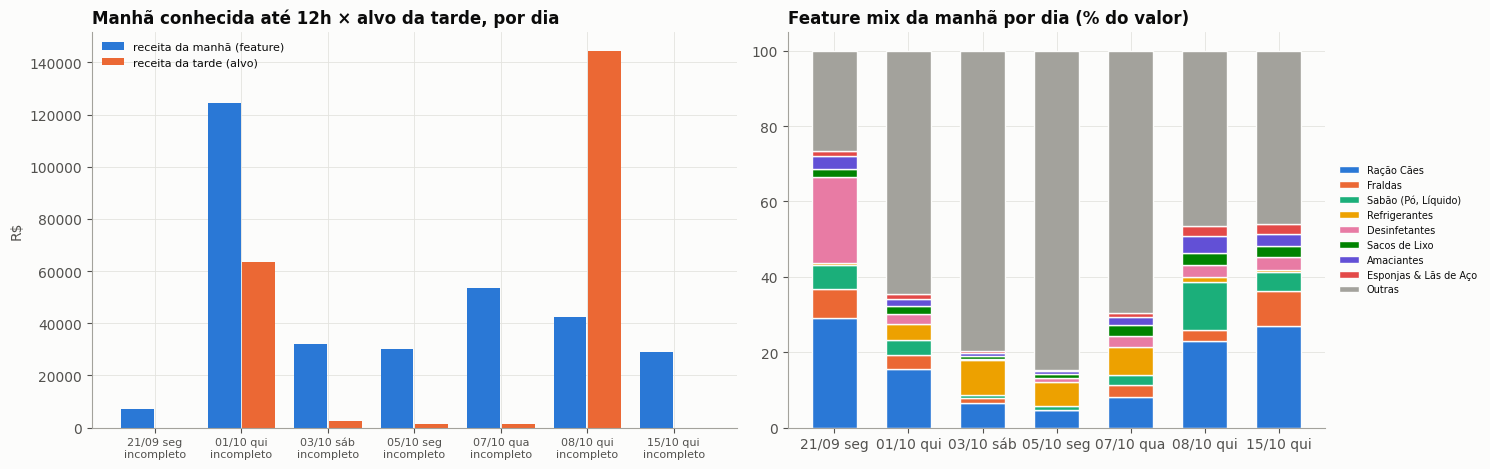

📌 Leitura
   • 7 dias na tabela, 0 completos; 5 dias têm alguma manhã e alguma tarde.
   • Nesses dias, a tarde rendeu 0,1× a manhã (mediana) — valor distorcido pelas horas faltantes, não usar como padrão.
   • receita_tarde_dia_anterior preenchida em 0 dia(s): depende de dia anterior completo.


In [0]:
secao("2.5", "Features do P1 por dia (manhã → tarde)")
COLUNAS_DIA = ["data", "dia_semana", "horas_manha_com_lote", "horas_tarde_com_lote", "dia_completo", "receita_manha", "pedidos_manha",
               "itens_por_pedido_manha", "pct_desconto_manha", "alvo_receita_tarde", "alvo_pedidos_tarde", "receita_tarde_dia_anterior"]
exibir(f_dia[[c for c in COLUNAS_DIA if c in f_dia.columns]].round(2), "Features do P1 por dia")

rotulos_dia = [f"{dia_txt(d)}\n{'completo' if c else 'incompleto'}" for d, c in zip(f_dia["data"], f_dia["dia_completo"].astype(bool))]
mix_manha = f_dia.set_index("data")[[f"pct_valor_{g}_manha" for g in GRUPOS_MIX if f"pct_valor_{g}_manha" in f_dia.columns]].dropna(how="all")
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
posicoes = np.arange(len(f_dia))
eixo1.bar(posicoes - 0.2, f_dia["receita_manha"], width=0.38, color=CORES[0], label="receita da manhã (feature)")
eixo1.bar(posicoes + 0.2, f_dia["alvo_receita_tarde"], width=0.38, color=CORES[1], label="receita da tarde (alvo)")
eixo1.set_xticks(posicoes, rotulos_dia, fontsize=8)
eixo1.set_ylabel("R$")
eixo1.legend(fontsize=8)
eixo1.set_title("Manhã conhecida até 12h × alvo da tarde, por dia")
base = np.zeros(len(mix_manha))
for g in GRUPOS_MIX:
    coluna = f"pct_valor_{g}_manha"
    if coluna in mix_manha:
        eixo2.bar([dia_txt(d) for d in mix_manha.index], mix_manha[coluna].fillna(0).values, bottom=base, color=COR_GRUPO.get(g, CINZA),
                  label=NOME_GRUPO.get(g, g), width=0.6, edgecolor=FUNDO, linewidth=1)
        base += mix_manha[coluna].fillna(0).values
eixo2.set_title("Feature mix da manhã por dia (% do valor)")
eixo2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
mostrar()
com_os_dois = f_dia[(f_dia["receita_manha"] > 0) & (f_dia["alvo_receita_tarde"] > 0)]
leitura(f"{len(f_dia)} dias na tabela, {DIAS_COMPLETOS} completos; {len(com_os_dois)} dias têm alguma manhã e alguma tarde.",
        (f"Nesses dias, a tarde rendeu {br((com_os_dois['alvo_receita_tarde'] / com_os_dois['receita_manha']).median(), 1)}× a manhã (mediana) — "
         "valor distorcido pelas horas faltantes, não usar como padrão." if len(com_os_dois) else "Nenhum dia tem manhã e tarde ao mesmo tempo."),
        f"receita_tarde_dia_anterior preenchida em {int(f_dia['receita_tarde_dia_anterior'].notna().sum())} dia(s): depende de dia anterior completo.")

## 2.6 Padrões que as features já mostram
Correlação de cada feature com a **receita da hora**, nas horas com micro-lote. Separamos o que é conhecido **antes** da hora (lags, média, calendário — usáveis na previsão)
do que é da **mesma hora** (descreve o padrão, e no P1 entra pela versão "da manhã").
⚠️ Com poucas horas observadas, isto é **indicativo**: mostra que as colunas carregam sinal, não é seleção de features.

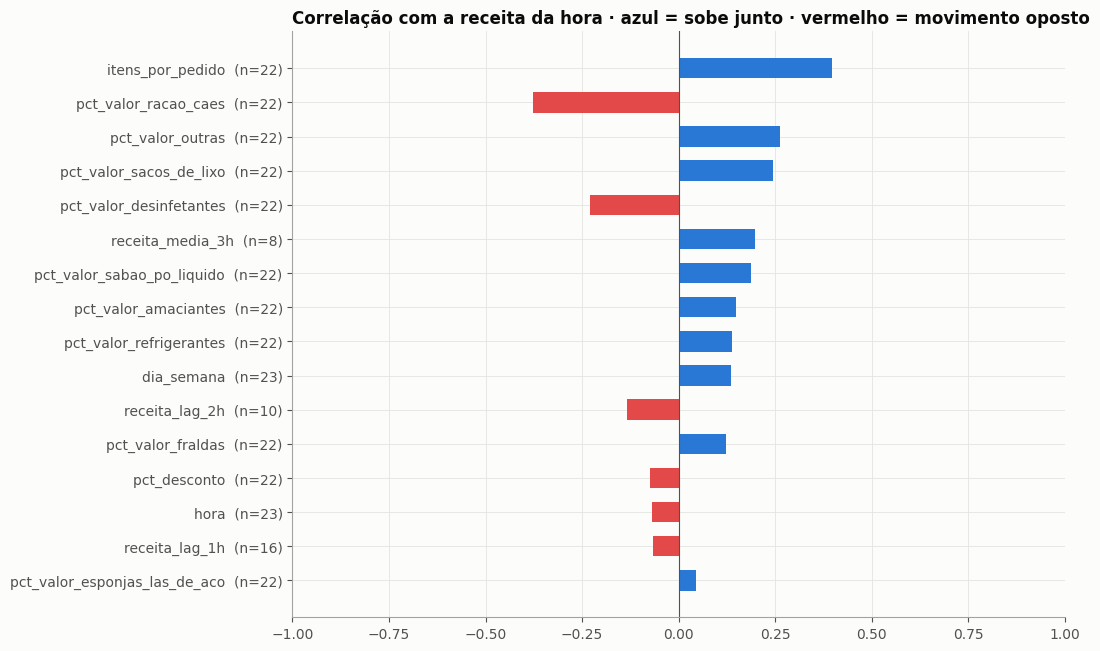

feature,descricao,correlacao,n_horas,conhecida_antes_da_hora
itens_por_pedido,itens ÷ pedidos,0.398,22,não
pct_valor_racao_caes,% do valor bruto em Ração Cães,-0.378,22,não
pct_valor_outras,% do valor bruto em Outras,0.262,22,não
pct_valor_sacos_de_lixo,% do valor bruto em Sacos de Lixo,0.244,22,não
pct_valor_desinfetantes,% do valor bruto em Desinfetantes,-0.229,22,não
receita_media_3h,média de receita nas 3 h anteriores,0.197,8,sim
pct_valor_sabao_po_liquido,"% do valor bruto em Sabão (Pó, Líquido)",0.188,22,não
pct_valor_amaciantes,% do valor bruto em Amaciantes,0.15,22,não
pct_valor_refrigerantes,% do valor bruto em Refrigerantes,0.138,22,não
dia_semana,0 = segunda … 6 = domingo,0.135,23,sim


📌 Leitura
   • Maior correlação: itens_por_pedido (0,40, n = 22 horas).
   • 2 de 16 features com |correlação| ≥ 0,3: há sinal para o modelo explorar.
   • Ficaram de fora por terem menos de 5 horas observadas: receita_lag_24h.


In [0]:
secao("2.6", "Padrões que as features já mostram")
candidatas = (["hora", "dia_semana", "itens_por_pedido", "pct_desconto"] + [f"pct_valor_{g}" for g in GRUPOS_MIX]
              + ["receita_lag_1h", "receita_lag_2h", "receita_lag_24h", "receita_media_3h"])
sinal = []
for c in candidatas:
    par = horas_obs[[c, "receita"]].dropna() if c in horas_obs else pd.DataFrame()
    if len(par) >= 5 and par[c].nunique() > 1:
        sinal.append({"feature": c, "descricao": descrever(c), "correlacao": round(par.corr().iloc[0, 1], 3), "n_horas": len(par),
                      "conhecida_antes_da_hora": "sim" if re.search(r"lag|media|hora|dia_semana", c) else "não"})
sinal = pd.DataFrame(sinal, columns=["feature", "descricao", "correlacao", "n_horas", "conhecida_antes_da_hora"])
if len(sinal):
    sinal = sinal.reindex(sinal["correlacao"].abs().sort_values(ascending=False).index).reset_index(drop=True)
    fig, eixo = plt.subplots(figsize=(11, 0.32 * len(sinal) + 1.5))
    ordem = sinal.iloc[::-1]
    barras = eixo.barh([f"{f}  (n={n})" for f, n in zip(ordem["feature"], ordem["n_horas"])], ordem["correlacao"],
                       color=[CORES[0] if v >= 0 else CORES[7] for v in ordem["correlacao"]], height=0.6)
    eixo.axvline(0, color=TEXTO_2, linewidth=0.8)
    eixo.set_xlim(-1, 1)
    eixo.set_title("Correlação com a receita da hora · azul = sobe junto · vermelho = movimento oposto")
    plt.tight_layout()
    mostrar()
exibir(sinal, "Correlação com a receita da hora")
if len(sinal):
    leitura(f"Maior correlação: {sinal.loc[0, 'feature']} ({br(sinal.loc[0, 'correlacao'], 2)}, n = {sinal.loc[0, 'n_horas']} horas).",
            f"{(sinal['correlacao'].abs() >= 0.3).sum()} de {len(sinal)} features com |correlação| ≥ 0,3: há sinal para o modelo explorar.",
            (f"Ficaram de fora por terem menos de 5 horas observadas: {', '.join(c for c in candidatas if c not in set(sinal['feature']))}."
             if len(sinal) < len(candidatas) else "Todas as features candidatas tinham horas suficientes para a conta."))
else:
    leitura("Horas observadas insuficientes para medir correlação (mínimo de 5 por feature).")

## 2.7 Prontidão para o modelo
Checklist final das features: o que está pronto e o que ainda depende de dados.

In [0]:
secao("2.7", "Prontidão para o modelo")
grade_ok = (pd.to_datetime(f_hora["hora_local"]).diff().dropna() == pd.Timedelta(hours=1)).all()
vazio_ok = f_hora.loc[~f_hora["tem_micro_lote"].astype(bool), "receita"].isna().all()
mix_cols = [f"pct_valor_{g}" for g in GRUPOS_MIX]
mix_ok = ((horas_obs.loc[horas_obs["itens"] > 0, mix_cols].sum(axis=1) - 100).abs() < 0.01).all()
num_pedido = f_pedido.drop(columns=["id_pedido"]).select_dtypes("number")
prontidao = pd.DataFrame([
    ("Features por pedido sem vazio", f"{int(num_pedido.isna().sum().sum())} vazios em {num_pedido.shape[1]} colunas", selo(not num_pedido.isna().any().any())),
    ("Um registro por pedido", f"{br(len(f_pedido))} linhas · {br(f_pedido['id_pedido'].nunique())} pedidos", selo(f_pedido["id_pedido"].is_unique, grave=True)),
    ("Grade de horas contínua", f"{len(f_hora)} horas seguidas", selo(grade_ok, grave=True)),
    ("Hora sem micro-lote = vazio (não zero)", f"{len(f_hora) - len(horas_obs)} horas vazias", selo(vazio_ok, grave=True)),
    ("Mix somando 100% por hora", "todas as horas com itens" if mix_ok else "há horas fora", selo(mix_ok)),
    ("Lag de 24h (baseline) disponível", f"{pct(PCT_LAG24)} das horas com micro-lote", selo(PCT_LAG24 >= 50, grave=True)),
    ("Dias completos para treino", f"{DIAS_COMPLETOS} (mínimo {DIAS_MINIMOS_TREINO})", selo(DIAS_COMPLETOS >= DIAS_MINIMOS_TREINO, grave=True)),
    ("Recalculável quando chegar dado novo", "este notebook relê todo o raw e sobrescreve", selo(True)),
], columns=["item", "situação", "status"])
exibir(prontidao, "Prontidão para o modelo")
prontos = prontidao["status"].str.startswith("✅").sum()
leitura(f"{prontos} de {len(prontidao)} itens prontos. O que falta depende só de volume de dados (dias completos e dias seguidos), não de código.")

item,situação,status
Features por pedido sem vazio,0 vazios em 28 colunas,✅ ok
Um registro por pedido,2.375 linhas · 2.375 pedidos,✅ ok
Grade de horas contínua,600 horas seguidas,✅ ok
Hora sem micro-lote = vazio (não zero),577 horas vazias,✅ ok
Mix somando 100% por hora,todas as horas com itens,✅ ok
Lag de 24h (baseline) disponível,"4,3% das horas com micro-lote",❌ bloqueia
Dias completos para treino,0 (mínimo 14),❌ bloqueia
Recalculável quando chegar dado novo,este notebook relê todo o raw e sobrescreve,✅ ok


📌 Leitura
   • 6 de 8 itens prontos. O que falta depende só de volume de dados (dias completos e dias seguidos), não de código.


## 2.8 Validação · o que foi pedido × o que entregamos
Confere, **automaticamente e com os dados desta execução**, cada exigência das duas tarefas da semana e da planilha `machine_learning_squad_2`
(linha da dupla: *P1 · Previsão de vendas da tarde · base itens · LightGBM com lags · features: lags de 1 a 24h, média móvel, hora, dia da semana e mix de categorias ·
mesma janela de teste da dupla 3 · métricas MAE, WAPE e RMSE contra o baseline "mesma hora do dia anterior"*).

**Status:** ✅ atendido · ⚠️ atendido em parte · ❌ não atendido · ⏭️ próxima etapa (não é desta semana).

origem,exigência,resultado nesta execução,onde ver,status
Tarefa 1 · EDA,Entender se os dados estão adequados,"0 problemas de chave · ligações 100,0% · 4,9% de itens inválidos · 0 dias completos para treino",12_ml_eda_itens · 1.3 · 1.4 · 1.9,✅ atendido
Tarefa 1 · EDA,Conhecer a tabela,"6 colunas perfiladas · fórmula do valor_total em 100,0% · 123 categorias",12_ml_eda_itens · 1.1 · 1.2 · 1.5 · 1.6 · 1.7,✅ atendido
Tarefa 1 · EDA,Gerar insights relacionados ao que o modelo vai usar,"7 insights, cada um com o uso no modelo",12_ml_eda_itens · 1.8 · 1.9,✅ atendido
Planilha · P1,Base da etapa 1: itens (ecommerce_itens_pedido),14.196 itens de 379 micro-lotes,Etapa 2,✅ atendido
Planilha · P1,Dados de entrada: ecommerce_pedidos e ecommerce_itens_pedido,pedidos: 2.375 · itens: 14.196,Etapa 2,✅ atendido
Planilha · P1,Alvo: receita e nº de pedidos entre 12h e 18h,colunas alvo_receita_tarde e alvo_pedidos_tarde em ml_features_p1_dia,Etapa 6 · 2.5,✅ atendido
Planilha · P1,A partir do movimento da manhã,"14 features da manhã, só com o que chegou até 12h",Etapa 6 · 2.5,✅ atendido
Planilha · dupla,Lags de 1 a 24h,"lags feitos: 1h, 2h, 3h, 4h, 5h, 6h, 7h, 8h, 9h, 10h, 11h, 12h, 13h, 14h, 15h, 16h, 17h, 18h, 19h, 20h, 21h, 22h, 23h, 24h",2.4,✅ atendido
Planilha · dupla,Média móvel,"receita_media_3h, pedidos_media_3h",2.4,✅ atendido
Planilha · dupla,Hora e dia da semana,"colunas hora, dia_semana e fim_de_semana",2.2 · 2.4,✅ atendido


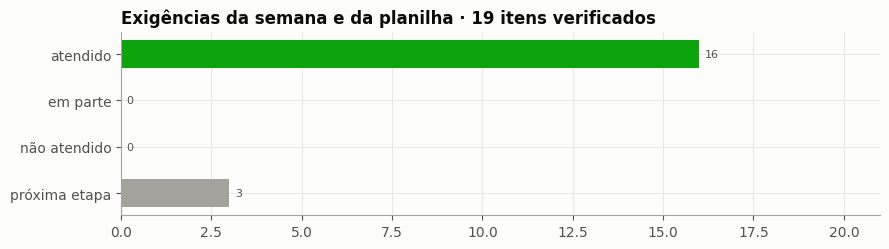

📌 Leitura
   • Desta semana: 16 de 16 exigências atendidas e 0 em parte.
   • Todos os lags de 1 a 24h pedidos na planilha estão presentes.
   • Próxima etapa (não é desta semana): baseline, janela de teste da dupla 3 e métricas MAE/WAPE/RMSE — dependem de dias completos para treinar.


In [0]:
secao("2.8", "Validação · o que foi pedido × o que entregamos")
contar_status = contar = lambda serie, inicio: int(serie.astype(str).str.startswith(inicio).sum())
lags_feitos = sorted(int(m.group(1)) for c in f_hora.columns if (m := re.fullmatch(r"receita_lag_(\d+)h", c)))
lags_faltando = [h for h in range(1, 25) if h not in lags_feitos]
cols_manha = [c for c in f_dia.columns if c.endswith("_manha")]
cols_mix = [c for c in f_hora.columns if c.startswith("pct_valor_")]
nao_numericas = [c for df in (f_pedido, f_hora, f_dia) for c in df.columns if c not in df.select_dtypes("number").columns]
padroes = int((sinal["correlacao"].abs() >= 0.3).sum()) if len(sinal) else 0


def item(fonte_req, requisito, ok, resultado, onde, parcial=False, proxima=False, grave=False):
    status = "⏭️ próxima etapa" if proxima else ("✅ atendido" if ok else ("⚠️ em parte" if parcial else ("❌ não atendido" if grave else "⚠️ em parte")))
    return {"origem": fonte_req, "exigência": requisito, "resultado nesta execução": resultado, "onde ver": onde, "status": status}


sem_eda = "rode antes o 12_ml_eda_itens"
cob_min = min(eda("cob_pedido", 0), eda("cob_sku", 0)) if EDA else None
validacao = pd.DataFrame([
    item("Tarefa 1 · EDA", "Entender se os dados estão adequados", bool(EDA) and eda("n_dup") + eda("n_chave_vazia") == 0 and cob_min >= 99,
         (f"{eda('n_dup') + eda('n_chave_vazia')} problemas de chave · ligações {pct(cob_min)} · {pct(eda('pct_invalidos'))} de itens inválidos · "
          f"{eda('dias_completos')} dias completos para treino" if EDA else sem_eda), "12_ml_eda_itens · 1.3 · 1.4 · 1.9", parcial=not EDA),
    item("Tarefa 1 · EDA", "Conhecer a tabela", bool(EDA) and eda("n_colunas_perfil") == eda("n_colunas_itens") and eda("pct_melhor", 0) >= 95,
         (f"{eda('n_colunas_perfil')} colunas perfiladas · fórmula do valor_total em {pct(eda('pct_melhor'))} · {eda('n_categorias')} categorias"
          if EDA else sem_eda), "12_ml_eda_itens · 1.1 · 1.2 · 1.5 · 1.6 · 1.7", parcial=not EDA),
    item("Tarefa 1 · EDA", "Gerar insights relacionados ao que o modelo vai usar", bool(EDA) and eda("n_insights", 0) >= 5,
         f"{eda('n_insights')} insights, cada um com o uso no modelo" if EDA else sem_eda, "12_ml_eda_itens · 1.8 · 1.9", parcial=not EDA),
    item("Planilha · P1", "Base da etapa 1: itens (ecommerce_itens_pedido)", len(brutos["itens"]) > 0,
         f"{br(len(brutos['itens']))} itens de {len(por_tabela['itens'])} micro-lotes", "Etapa 2"),
    item("Planilha · P1", "Dados de entrada: ecommerce_pedidos e ecommerce_itens_pedido", len(brutos["pedidos"]) > 0 and len(brutos["itens"]) > 0,
         f"pedidos: {br(len(pedidos))} · itens: {br(len(itens))}", "Etapa 2"),
    item("Planilha · P1", "Alvo: receita e nº de pedidos entre 12h e 18h", {"alvo_receita_tarde", "alvo_pedidos_tarde"} <= set(f_dia.columns),
         "colunas alvo_receita_tarde e alvo_pedidos_tarde em ml_features_p1_dia", "Etapa 6 · 2.5"),
    item("Planilha · P1", "A partir do movimento da manhã", len(cols_manha) > 0,
         f"{len(cols_manha)} features da manhã, só com o que chegou até 12h", "Etapa 6 · 2.5"),
    item("Planilha · dupla", "Lags de 1 a 24h", not lags_faltando,
         f"lags feitos: {', '.join(f'{h}h' for h in lags_feitos) or 'nenhum'}" + (f" · faltam {len(lags_faltando)} (de {lags_faltando[0]}h a {lags_faltando[-1]}h)" if lags_faltando else ""),
         "2.4", parcial=bool(lags_feitos)),
    item("Planilha · dupla", "Média móvel", any(re.fullmatch(r"receita_media_\d+h", c) for c in f_hora.columns),
         ", ".join(c for c in f_hora.columns if re.fullmatch(r"(receita|pedidos)_media_\d+h", c)), "2.4"),
    item("Planilha · dupla", "Hora e dia da semana", {"hora", "dia_semana"} <= set(f_hora.columns), "colunas hora, dia_semana e fim_de_semana", "2.2 · 2.4"),
    item("Planilha · dupla", "Mix de categorias", len(cols_mix) > 0, f"{len(cols_mix)} colunas pct_valor_<categoria> por hora (+ versão da manhã por dia)", "1.8 · 2.4 · 2.5"),
    item("Orientação · Geovany", "Transformar colunas categóricas em numéricas", CODIFICACAO_OK,
         f"{N_CATEGORICAS} categóricas → {N_ONE_HOT} colunas 0/1 (one-hot) · sim/não → 0/1 · nenhum texto fora das chaves", "Etapa 8"),
    item("Orientação · Geovany", "Normalizar para servir de entrada ao modelo", NORMALIZACAO_OK and (all(gravadas_modelo) if GRAVAR else True),
         f"{N_NORMALIZADAS} colunas padronizadas (média 0, desvio 1) · tabelas ml_modelo_* gravadas · parâmetros em metadata/", "Etapa 8"),
    item("Tarefa 2 · Features", "Preparar os dados para o modelo", grade_ok and vazio_ok and len(gravadas) == 3,
         f"3 tabelas Delta · grade horária contínua ({len(f_hora)} horas) · hora sem micro-lote = vazio", "2.1 · 2.7"),
    item("Tarefa 2 · Features", "Criar colunas numéricas", N_FEATURES > 0,
         f"{N_FEATURES} colunas numéricas · não numéricas só de identificação: {', '.join(sorted(set(nao_numericas)))}", "2.2"),
    item("Tarefa 2 · Features", "Que ajudem a identificar padrões", padroes > 0,
         f"{padroes} features com |correlação| ≥ 0,3 com a receita da hora · correlações por pedido", "2.3 · 2.6", parcial=True),
    item("Planilha · dupla", "Baseline: mesma hora do dia anterior", False, f"coluna receita_lag_24h pronta, preenchida em {pct(PCT_LAG24)} das horas", "2.4", proxima=True),
    item("Planilha · dupla", "Mesma janela de teste da dupla 3 (SARIMAX)", False, "a combinar com Leandro e Kauan", "seção 3", proxima=True),
    item("Planilha · P1", "Métricas MAE, WAPE e RMSE contra o baseline", False, f"depende do treino: {DIAS_COMPLETOS} dias completos (mínimo {DIAS_MINIMOS_TREINO})", "1.9 · seção 3", proxima=True),
])
exibir(validacao, "Validação: o que foi pedido × o que entregamos", linhas=40)

contagem_status = validacao["status"].str.split(" ").str[0].value_counts()
fig, eixo = plt.subplots(figsize=(9, 2.6))
ordem_status = [("✅", "atendido", OK_COR), ("⚠️", "em parte", ALERTA_COR), ("❌", "não atendido", ERRO_COR), ("⏭️", "próxima etapa", CINZA)]
valores = [int(contagem_status.get(s, 0)) for s, _, _ in ordem_status]
barras = eixo.barh([r for _, r, _ in ordem_status][::-1], valores[::-1], color=[c for _, _, c in ordem_status][::-1], height=0.6)
rotular(eixo, barras, [str(v) for v in valores[::-1]], horizontal=True)
eixo.set_xlim(0, max(valores) * 1.25 + 1)
eixo.set_title(f"Exigências da semana e da planilha · {len(validacao)} itens verificados")
plt.tight_layout()
mostrar()

semana = validacao[~validacao["status"].str.startswith("⏭️")]
leitura(f"Desta semana: {contar(semana['status'], '✅')} de {len(semana)} exigências atendidas e {contar(semana['status'], '⚠️')} em parte.",
        (f"Em parte: lags de 1 a 24h — o notebook 12 cria {len(lags_feitos)} lags ({', '.join(f'{h}h' for h in lags_feitos)}); "
         f"para seguir a planilha ao pé da letra, basta ajustar LAGS_H no 12." if lags_faltando else "Todos os lags de 1 a 24h pedidos na planilha estão presentes."),
        f"Próxima etapa (não é desta semana): baseline, janela de teste da dupla 3 e métricas MAE/WAPE/RMSE — dependem de dias completos para treinar.")

---
# 3 · Conclusões, decisão necessária e próximos passos

In [0]:
secao("3", "Conclusões")
print("🧭 EDA · 12_ml_eda_itens" + (f" (execução de {EDA['gerado_em']})" if EDA else " · resultados não encontrados: rode antes o 12_ml_eda_itens"))
if EDA:
    print(f"   • Tabela de itens íntegra ({eda('n_dup') + eda('n_chave_vazia')} problemas de chave) e ligada a pedidos e catálogo ({pct(cob_min)}).")
    print(f"   • valor_total = {eda('melhor_conta')} em {pct(eda('pct_melhor'))} dos pedidos; frete fora.")
    print(f"   • {pct(eda('pct_invalidos'))} de itens inválidos, marcados e tratados nas features.")
    print(f"   • 3 maiores categorias = {pct(eda('top3_pct'), 0)} do valor"
          + (f"; mix muda até {br(eda('mix_max_pp'), 1)} p.p. entre manhã e tarde." if eda("mix_max_pp") is not None else "."))
print("🧮 Features · este notebook")
print(f"   • {N_FEATURES} colunas numéricas em 3 tabelas Delta: {br(len(f_pedido))} pedidos · {len(f_hora)} horas · {len(f_dia)} dias.")
print(f"   • Lags de 1 a 24h, média móvel, calendário, mix, atributos do produto e alvo da tarde; recalculam sozinhos com dado novo.")
print(f"   • Codificação e normalização: {N_CATEGORICAS} categóricas → {N_ONE_HOT} colunas 0/1 · {N_NORMALIZADAS} numéricas padronizadas · tabelas ml_modelo_*.")
semana = validacao[~validacao["status"].str.startswith("⏭️")]
print("✅ Validação")
print(f"   • {contar_status(semana['status'], '✅')} de {len(semana)} exigências desta semana atendidas; "
      f"{contar_status(validacao['status'], '⏭️')} são da etapa de treino.")
print("🚧 Para o treino (próxima semana)")
print(f"   • {DIAS_COMPLETOS} dias completos (mínimo {DIAS_MINIMOS_TREINO}), lag de 24h em {pct(PCT_LAG24)} das horas, gerador parado há {DIAS_SEM_DADO} dias.")

🧭 EDA · 12_ml_eda_itens (execução de 11/08/2026 02:55:15)
   • Tabela de itens íntegra (0 problemas de chave) e ligada a pedidos e catálogo (100,0%).
   • valor_total = Σ qtd × preço − desconto por unidade em 100,0% dos pedidos; frete fora.
   • 4,9% de itens inválidos, marcados e tratados nas features.
   • 3 maiores categorias = 31% do valor; mix muda até 27,2 p.p. entre manhã e tarde.
🧮 Features · este notebook
   • 121 colunas numéricas em 3 tabelas Delta: 2.375 pedidos · 600 horas · 7 dias.
   • Lags de 1 a 24h, média móvel, calendário, mix, atributos do produto e alvo da tarde; recalculam sozinhos com dado novo.
   • Codificação e normalização: 4 categóricas → 28 colunas 0/1 · 114 numéricas padronizadas · tabelas ml_modelo_*.
✅ Validação
   • 16 de 16 exigências desta semana atendidas; 3 são da etapa de treino.
🚧 Para o treino (próxima semana)
   • 0 dias completos (mínimo 14), lag de 24h em 4,3% das horas, gerador parado há 25 dias.


### 🗓️ Orientação do Geovany
- Esta semana: **EDA + engenharia de features**, incluindo **transformar as categóricas em numéricas e normalizá-las** para servir de entrada ao modelo (Etapa 8).
- **Próxima semana:** implementar o modelo (LightGBM com lags).
- **Mais à frente:** comparar com a outra dupla do P1 (Leandro e Kauan · SARIMAX), na mesma janela de teste.

### ▶️ Próximos passos
1. Próxima semana: treinar o LightGBM do P1 com as tabelas `ml_modelo_*` e comparar com o baseline "mesma hora do dia anterior" (MAE, WAPE, RMSE).
2. Resolver o volume de dados para treino: hoje não há dias com manhã e tarde completas (gerador parado). Levar o tema ao Geovany quando o treino começar.
3. Com dados novos: rodar de novo o `12_ml_eda_itens` e o `13_ml_features_itens`, nessa ordem.

---
# 4 · Relatório completo · EDA e Engenharia de Features
**Faz:** junta a Parte 1 (EDA, do `12_ml_eda_itens`) e a Parte 2 (features, desta execução) com **o que foi feito**, **o que obtivemos**, a **interpretação** e o **impacto no modelo** de cada etapa, a validação e o **roteiro** da apresentação, e grava em `docs/13_ml_features_itens/` (o relatório não aparece no notebook).
**Valida:** que os arquivos foram gravados e que a Parte 1 foi encontrada.

In [0]:
SECAO_ATUAL = None
FIM = pd.Timestamp.now(tz="America/Sao_Paulo").tz_localize(None)
DURACAO_S = time.time() - INICIO
contar = lambda serie, inicio: int(serie.astype(str).str.startswith(inicio).sum())


def interpretar_todas(funcoes):
    """Roda cada interpretação; uma etapa que falhou não impede o relatório das outras."""
    saida = {}
    for codigo, funcao in funcoes.items():
        try:
            saida[codigo] = funcao()
        except Exception as erro:
            saida[codigo] = ("—", f"Não foi possível interpretar nesta execução ({type(erro).__name__}: {erro}).", "—")
    return saida

def interpretar_2_0():
    return ("Transforma as colunas categóricas em numéricas (sim/não → 0/1, one-hot com os valores mais frequentes + 'outras') e padroniza as numéricas "
            "(média 0, desvio 1), gravando as tabelas ml_modelo_* e os parâmetros da normalização.",
            f"{N_CATEGORICAS} colunas categóricas viraram {N_ONE_HOT} colunas 0/1 e {N_NORMALIZADAS} colunas numéricas foram padronizadas; "
            + ("nenhuma coluna de texto sobrou fora das chaves e todas as normalizadas ficaram com média 0 e desvio 1. "
               if CODIFICACAO_OK and NORMALIZACAO_OK else "há pendências na conferência (ver validação). ")
            + "Os alvos ficaram na escala real, para o modelo prever em R$ e em nº de pedidos.",
            "As tabelas ml_modelo_* são a entrada direta do modelo da próxima semana; a média e o desvio salvos garantem a mesma conta em dados novos.")


def interpretar_2_1():
    return ("Apresenta as 3 tabelas de features gravadas nas Etapas 1 a 7 e um pedido real antes (linhas de itens) e depois (1 linha de features).",
            "As features estão em 3 granularidades complementares: "
            + ", ".join(f"{t} ({br(l)} linhas)" for t, l in zip(visao["tabela"], visao["linhas"]))
            + f". No exemplo, {len(antes)} linhas de itens viram 1 linha sem perder valor (soma dos itens = valor_total).",
            "A tabela por pedido serve ao P3 e ao agregado do P1; as tabelas por hora e por dia são a entrada direta do LightGBM do P1.")


def interpretar_2_2():
    por_tabela_n = dicionario.groupby("tabela").size()
    return ("Documenta cada feature numérica: tabela, como é calculada e o resumo dos valores (vazios, mínimo, média, máximo).",
            f"{len(dicionario)} features numéricas ({por_tabela_n.get('pedido', 0)} por pedido, {por_tabela_n.get('hora', 0)} por hora e "
            f"{por_tabela_n.get('dia', 0)} por dia), todas com descrição. Por pedido não há vazios; os vazios por hora e por dia são intencionais "
            "(horas sem micro-lote e lags sem a hora anterior).",
            "O LightGBM aceita vazios nativamente, então não é preciso inventar valores para as horas sem dado.")


def interpretar_2_3():
    texto = (f"A feature mais ligada ao valor do pedido é {corr_valor.index[0]} (correlação {br(corr_valor.iloc[0], 2)}). Há redundância entre "
             f"{pares.iloc[0]['feature_a']} e {pares.iloc[0]['feature_b']} ({br(pares.iloc[0]['correlacao'], 2)}).")
    if "diferenca_pct" in perfil_periodo:
        texto += f" Entre manhã e tarde, a maior diferença está em {muda} ({br(perfil_periodo.loc[muda, 'diferenca_pct'], 1)}% à tarde)."
    return ("Mostra a distribuição das features por pedido, as correlações entre elas e o perfil do pedido da manhã × da tarde.", texto,
            "Base para o P3 (valor do pedido) e para retirar features redundantes antes de treinar.")


def interpretar_2_4():
    return ("Mostra a grade horária completa, onde há dado, quanto dos lags é calculável e como receita, lag e média móvel se comportam num dia real.",
            f"Só {pct(100 * len(horas_obs) / len(f_hora))} das horas da grade têm micro-lote. Nelas, o lag de 1h existe em "
            f"{pct(conhecido.get('receita_lag_1h', 0))} e o de 24h (baseline) em só {pct(conhecido.get('receita_lag_24h', 0))}. "
            f"Receita média por hora observada: {reais(horas_obs['receita'].mean())}.",
            "Sem dias seguidos, o baseline 'mesma hora do dia anterior' quase não pode ser calculado — é o principal limite para comparar o LightGBM com o baseline.")


def interpretar_2_5():
    return ("Mostra a tabela do P1 por dia: o que se sabe da manhã até 12h (features) e a receita e os pedidos da tarde (alvo).",
            f"{len(f_dia)} dias na tabela e {DIAS_COMPLETOS} completos. Os dias têm manhã ou tarde incompletas por causa dos horários em que o gerador rodou, "
            "então a relação manhã × tarde ainda não é confiável.",
            "A tabela está pronta: quando houver dias completos, basta filtrar dia_completo = True para treinar.")


def interpretar_2_6():
    if not len(sinal):
        return ("Mede a correlação das features com a receita da hora.", "Horas observadas insuficientes para medir correlação.",
                "Reavaliar quando houver mais dados.")
    fortes = int((sinal["correlacao"].abs() >= 0.3).sum())
    return ("Mede a correlação de cada feature com a receita da hora, separando o que é conhecido antes da hora (lags, calendário) do que é da mesma hora.",
            f"{fortes} de {len(sinal)} features têm |correlação| ≥ 0,3 com a receita; a maior é {sinal.loc[0, 'feature']} "
            f"({br(sinal.loc[0, 'correlacao'], 2)}, n = {sinal.loc[0, 'n_horas']} horas). Com poucas horas, o resultado é indicativo.",
            "As colunas carregam sinal; a seleção definitiva virá da importância de variáveis do LightGBM.")


def interpretar_2_7():
    pendentes = prontidao.loc[~prontidao["status"].astype(str).str.startswith("✅"), "item"].tolist()
    return ("Checklist final das features: o que está pronto e o que ainda depende de dados.",
            f"{contar(prontidao['status'], '✅')} de {len(prontidao)} itens prontos. " + (f"Pendentes: {'; '.join(pendentes)}." if pendentes else "Nada pendente."),
            "O que falta depende de dados, não de código: este notebook recalcula tudo quando chegar dado novo.")


def interpretar_2_8():
    semana = validacao[~validacao["status"].str.startswith("⏭️")]
    parciais = semana.loc[semana["status"].str.startswith("⚠️"), "exigência"].tolist()
    return ("Confere cada exigência das duas tarefas da semana e da planilha machine_learning_squad_2 contra o que os notebooks produziram nesta execução.",
            f"{contar(semana['status'], '✅')} de {len(semana)} exigências desta semana estão atendidas"
            + (f"; em parte: {'; '.join(parciais)}." if parciais else ".")
            + f" {contar(validacao['status'], '⏭️')} itens da planilha são da próxima etapa (baseline, janela de teste e métricas).",
            "Mostra ao Geovany, item a item, que as tarefas da semana foram cumpridas e o que fica para a etapa de treino.")


def celula_texto(valor, markdown=False):
    texto = br(valor, 2) if isinstance(valor, float) else str(valor).replace("\n", " ")
    return texto.replace("|", "\\|") if markdown else texto        # "|" quebraria a tabela markdown


def tabela_md(tabela):
    colunas = [celula_texto(c, markdown=True) for c in tabela.columns]
    linhas = ["| " + " | ".join(colunas) + " |", "|" + "---|" * len(colunas)]
    linhas += ["| " + " | ".join(celula_texto(v, markdown=True) for v in linha) + " |" for linha in tabela.itertuples(index=False)]
    return "\n".join(linhas)


def tabela_html(tabela):
    cabecalho = "".join(f"<th>{html_lib.escape(str(c))}</th>" for c in tabela.columns)
    corpo = "".join("<tr>" + "".join(f"<td>{html_lib.escape(celula_texto(v))}</td>" for v in linha) + "</tr>" for linha in tabela.itertuples(index=False))
    return f'<div class="rolagem"><table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table></div>'


def cartoes_tabela(lista):
    estado = {"ok": "✅", "alerta": "⚠️", "erro": "❌", None: ""}
    return pd.DataFrame([(r, v, n, estado[e]) for r, v, n, e in lista], columns=["indicador", "valor", "detalhe", "status"])


ESTILO = """<style>
body{font-family:-apple-system,Segoe UI,Roboto,sans-serif;background:#fcfcfb;color:#0b0b0b;margin:0;padding:24px 16px;line-height:1.5}
main{max-width:1100px;margin:0 auto} h1{font-size:26px;margin:0 0 8px} h2{margin-top:36px;border-bottom:2px solid #2a78d6;padding-bottom:4px}
h3{margin-top:28px} .info{color:#52514e;font-size:14px} section{border-top:1px solid #e4e3df;padding-top:8px} h2+section{border-top:none}
.interp{background:#eef4fc;border-left:4px solid #2a78d6;padding:8px 12px} .impacto{background:#f4f3f0;border-left:4px solid #a3a29c;padding:8px 12px}
.rotulo{font-weight:600;margin-bottom:4px} .rolagem{overflow-x:auto} table{border-collapse:collapse;font-size:13px;margin:6px 0 14px}
th,td{border:1px solid #e4e3df;padding:4px 8px;text-align:left;vertical-align:top} th{background:#f0efec}
img{max-width:100%;border:1px solid #e4e3df;margin:8px 0}
</style>"""


def montar_relatorio(titulo, nome_notebook, subpasta, ordem, registro, interpretacao, partes, cabecalho_info, extra_md=(), extra_html=""):
    """Monta o relatório (.md e .html com gráficos), grava em docs/<subpasta>/ e atualiza o indice.md. Devolve (pasta, arquivos gravados)."""
    md = [f"# 📊 {titulo}", "", *[f"- **{k}:** {v}" for k, v in cabecalho_info], "",
          f"> Relatório gerado automaticamente a cada execução do `{nome_notebook}`. Os números vêm das execuções indicadas acima. "
          "Os gráficos estão no arquivo `.html` de mesmo nome.", ""]
    secoes_html, parte_atual = [], None
    for codigo in ordem:
        reg = registro[codigo]
        feito, interp, impacto = interpretacao.get(codigo, ("—", "—", "—"))
        parte = codigo.split(".")[0]
        if parte != parte_atual:                        # título da parte (no resumo, ele já é o título da seção)
            parte_atual = parte
            md += ["---", f"## {partes[parte]}", ""]
            secoes_html.append(f"<h2>{partes[parte]}</h2>")
        blocos = []
        if "." in codigo:
            titulo_secao = f"{codigo} · {reg['titulo']}"
            md += [f"### {titulo_secao}", ""]
            blocos.append(f"<h3>{html_lib.escape(titulo_secao)}</h3>")
        md += [f"**O que foi feito:** {feito}", ""]
        blocos.append(f"<p><b>O que foi feito:</b> {html_lib.escape(feito)}</p>")
        if reg.get("cartoes"):
            md += [tabela_md(cartoes_tabela(reg["cartoes"])), ""]
            blocos.append(tabela_html(cartoes_tabela(reg["cartoes"])))
        if reg.get("leituras"):
            md += ["**O que obtivemos:**", "", *[f"- {l}" for l in reg["leituras"]], ""]
            blocos.append("<p><b>O que obtivemos:</b></p><ul>" + "".join(f"<li>{html_lib.escape(l)}</li>" for l in reg["leituras"]) + "</ul>")
        md += [f"**Interpretação:** {interp}", "", f"**Impacto no modelo:** {impacto}", ""]
        blocos += [f'<p class="interp"><b>Interpretação:</b> {html_lib.escape(interp)}</p>',
                   f'<p class="impacto"><b>Impacto no modelo:</b> {html_lib.escape(impacto)}</p>']
        for nome, tabela in reg.get("tabelas", []):
            md += [f"**{nome}**", "", tabela_md(tabela), ""]
            blocos += [f"<p class='rotulo'>{html_lib.escape(nome)}</p>", tabela_html(tabela)]
        blocos += [f'<img src="data:image/png;base64,{f}" alt="gráfico da seção {codigo}">' for f in reg.get("figuras", [])]
        secoes_html.append(f'<section>{"".join(blocos)}</section>')
    md += list(extra_md)
    info = "".join(f"<div><b>{html_lib.escape(k)}:</b> {html_lib.escape(v)}</div>" for k, v in cabecalho_info)
    html = (f'<!doctype html><html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
            f"<title>{html_lib.escape(titulo)} · {FIM:%m/%d/%Y %H:%M:%S}</title>{ESTILO}</head><body><main>"
            f'<h1>📊 {html_lib.escape(titulo)}</h1><div class="info">{info}</div>{"".join(secoes_html)}{extra_html}</main></body></html>')

    pasta, gravados = pasta_docs(subpasta), []
    if pasta:
        nome_base = f"relatorio_{FIM:%m-%d-%Y_%H-%M-%S}"
        try:
            os.makedirs(pasta, exist_ok=True)
            for extensao, conteudo in [("md", "\n".join(md)), ("html", html)]:
                with open(os.path.join(pasta, f"{nome_base}.{extensao}"), "w", encoding="utf-8") as arquivo:
                    arquivo.write(conteudo)
                gravados.append(f"{nome_base}.{extensao}")
            execucoes = sorted((f for f in os.listdir(pasta) if re.fullmatch(r"relatorio_.+\.md", f)),
                               key=lambda f: pd.to_datetime(f[10:-3], format="%m-%d-%Y_%H-%M-%S"), reverse=True)
            with open(os.path.join(pasta, "indice.md"), "w", encoding="utf-8") as arquivo:
                arquivo.write(f"# 📚 Execuções do {nome_notebook}\n\nMais recente primeiro. Cada execução tem um `.md` (texto) e um `.html` (com gráficos).\n\n"
                              + "\n".join(f"- {pd.to_datetime(f[10:-3], format='%m-%d-%Y_%H-%M-%S'):%m/%d/%Y %H:%M:%S} · [{f}]({f}) · {f[:-3]}.html"
                                          for f in execucoes) + "\n")
        except OSError as erro:
            print(f"⚠️ Não foi possível gravar em {pasta}: {erro}")
    checar(len(gravados) == 2, f"Relatório gravado em {pasta}: {', '.join(gravados)} (+ indice.md)",
           "Relatório não gravado: o texto aparece abaixo", parar=False)
    if gravados:                                       # o relatório fica só em docs/, não no notebook
        print("📝 Relatório desta execução (abra na pasta docs/):")
        for arquivo in gravados + ["indice.md"]:
            print(f"   • {pasta}/{arquivo}")
    else:
        print("\n".join(md)[:3000])
    return pasta, gravados


semana = validacao[~validacao["status"].str.startswith("⏭️")]
# ------------------------------ roteiro: pedido × capturado ------------------------------
pedido_capturado = validacao.rename(columns={"origem": "tarefa", "exigência": "o que foi pedido", "resultado nesta execução": "o que capturamos"})[
    ["tarefa", "o que foi pedido", "onde ver", "o que capturamos", "status"]]
falas = [
    "Contexto: somos a dupla Eduardo e Aliedson, base de itens (ecommerce_itens_pedido), problema P1 — prever a receita e os pedidos da tarde com o que se sabe até 12h.",
    (f"Fonte: raw/real-time-data (streaming), {br(eda('n_lotes'))} micro-lotes entre {eda('primeiro_lote')} e {eda('ultimo_lote')}; "
     f"{br(eda('n_itens'))} itens e {br(eda('n_pedidos'))} pedidos." if EDA else "Fonte: raw/real-time-data (streaming) — detalhes no 12_ml_eda_itens."),
    (f"Tarefa 1 · a tabela é íntegra: {eda('n_dup')} ids repetidos, {eda('n_chave_vazia')} chaves vazias e {pct(cob_min)} de ligação com pedidos e catálogo."
     if EDA else "Tarefa 1 · rode o 12_ml_eda_itens para trazer os números da EDA."),
    (f"Descobrimos como o valor é formado: valor_total = {eda('melhor_conta')} ({pct(eda('pct_melhor'))} dos pedidos); o frete fica fora." if EDA else ""),
    (f"Qualidade: {pct(eda('pct_invalidos'))} dos itens têm quantidade, preço ou desconto inválido; marcamos sem apagar, porque o valor_total os inclui." if EDA else ""),
    (f"Padrões: pedido típico de {br(eda('mediana_itens_pedido'))} itens e {reais(eda('mediana_valor_pedido'))}; as 3 maiores categorias somam "
     f"{pct(eda('top3_pct'), 0)} do valor" + (f"; o mix muda até {br(eda('mix_max_pp'), 1)} p.p. entre manhã e tarde." if eda("mix_max_pp") is not None else ".")
     if EDA else ""),
    f"Tarefa 2 · features: {N_FEATURES} colunas numéricas em 3 tabelas Delta (pedido, hora, dia), com lags de 1h a 24h, média móvel, calendário, mix, atributos do produto e o alvo da tarde.",
    f"Como pedido: as {N_CATEGORICAS} colunas categóricas viraram {N_ONE_HOT} colunas 0/1 e {N_NORMALIZADAS} numéricas foram normalizadas (média 0, desvio 1), nas tabelas ml_modelo_*, prontas para o modelo.",
    f"Validação: {contar(semana['status'], '✅')} de {len(semana)} exigências desta semana atendidas (tarefas + planilha machine_learning_squad_2).",
    f"Bloqueio: {DIAS_COMPLETOS} dias completos (mínimo {DIAS_MINIMOS_TREINO}), lag de 24h em {pct(PCT_LAG24)} das horas e gerador parado há {DIAS_SEM_DADO} dias.",
    "Próxima semana: implementar o LightGBM do P1 com as tabelas ml_modelo_*; a comparação com o Leandro e o Kauan (SARIMAX) vem mais à frente.",
]
falas = [f for f in falas if f]
PENDENCIAS = ["Próxima semana: implementar o modelo (LightGBM com lags) com as tabelas ml_modelo_*.",
              "Volume de dados para treino: hoje não há dias com manhã e tarde completas (gerador parado) — levar ao Geovany quando o treino começar.",
              "Mais à frente: comparar com o SARIMAX do Leandro e do Kauan (mesma janela de teste, MAE, WAPE e RMSE).",
              "Com dados suficientes: rodar de novo o 12_ml_eda_itens e o 13_ml_features_itens e treinar o LightGBM do P1."]

codigos_features = ["2.0", "2.1", "2.2", "2.3", "2.4", "2.5", "2.6", "2.7", "2.8"]
interpretacao = interpretar_todas({c: globals()[f"interpretar_{c.replace('.', '_')}"] for c in codigos_features})
REGISTRO_TOTAL = {**EDA_REGISTRO, **{c: REGISTRO[c] for c in codigos_features if c in REGISTRO}}
ORDEM = [c for c in ["0", "1.1", "1.2", "1.3", "1.4", "1.5", "1.6", "1.7", "1.8", "1.9"] if c in EDA_REGISTRO] + [c for c in codigos_features if c in REGISTRO]
roteiro_md = ["---", "## 🧭 Roteiro · o que foi pedido × o que capturamos", "", tabela_md(pedido_capturado), "",
              "### 🎤 Roteiro da apresentação (falas sugeridas)", "", *[f"{i}. {f}" for i, f in enumerate(falas, 1)], "",
              "### 📌 Pendências", "", *[f"- {p}" for p in PENDENCIAS], ""]
roteiro_html = ("<h2>🧭 Roteiro · o que foi pedido × o que capturamos</h2>" + tabela_html(pedido_capturado)
                + "<h3>🎤 Roteiro da apresentação (falas sugeridas)</h3><ol>" + "".join(f"<li>{html_lib.escape(f)}</li>" for f in falas) + "</ol>"
                + "<h3>📌 Pendências</h3><ul>" + "".join(f"<li>{html_lib.escape(p)}</li>" for p in PENDENCIAS) + "</ul>")
montar_relatorio(
    "Relatório · EDA e Engenharia de Features da base de itens", "13_ml_features_itens", "13_ml_features_itens", ORDEM, REGISTRO_TOTAL,
    {**EDA_INTERP, **interpretacao}, {"0": "0 · Resumo da EDA", "1": "Parte 1 · Análise exploratória (EDA) · 12_ml_eda_itens",
                                      "2": "Parte 2 · Engenharia de features · 13_ml_features_itens"},
    [("Gerado em", f"{FIM:%m/%d/%Y} às {FIM:%H:%M:%S} (Brasília)"), ("Duração da execução", f"{br(DURACAO_S, 0)} s"),
     ("Notebooks", "12_ml_eda_itens (Tarefa 1" + (f", execução de {EDA['gerado_em']})" if EDA else ", resultados não encontrados)")
      + " · 13_ml_features_itens (Tarefa 2, esta execução)"),
     ("Dupla", "Squad 2 · Eduardo e Aliedson"), ("Base da etapa 1", "ecommerce_itens_pedido"),
     ("Problema", "P1 · previsão de vendas da tarde (LightGBM com lags)"), ("Fonte", "raw/real-time-data (streaming) + Silver")],
    roteiro_md, roteiro_html)
checar(bool(EDA_REGISTRO), f"Relatório completo: Parte 1 (EDA) com {len(EDA_REGISTRO)} seções + Parte 2 (features) com {len(ORDEM) - len(EDA_REGISTRO)}",
       "Relatório saiu só com as features: rode o 12_ml_eda_itens e depois este notebook", parar=False)

✅ Relatório gravado em /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/13_ml_features_itens: relatorio_11-09-2026_17-33-36.md, relatorio_11-09-2026_17-33-36.html (+ indice.md)
📝 Relatório desta execução (abra na pasta docs/):
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/13_ml_features_itens/relatorio_11-09-2026_17-33-36.md
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/13_ml_features_itens/relatorio_11-09-2026_17-33-36.html
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/13_ml_features_itens/indice.md
✅ Relatório completo: Parte 1 (EDA) com 10 seções + Parte 2 (features) com 9


# 📘 Documentação · 🧮 13_ml_features_itens - Engenharia de features da base de itens

## 📌 Projeto: Real-Time Ecommerce Analytics · ML em Streaming

**Squad:** Squad 2 · Eduardo e Aliedson
**Base da etapa 1:** itens (`ecommerce_itens_pedido`)
**Problema da dupla:** P1 · Previsão de vendas do período da tarde (LightGBM com lags)
**Tarefa:** 2 · Engenharia de features
**Entrada:** achados da EDA (`12_ml_eda_itens`) · **Saída:** três tabelas Delta de features + relatório completo em `docs/`

---

## 🎯 Objetivo

Preparar os dados para o modelo: criar colunas numéricas que ajudem a identificar padrões, por pedido, por hora e por dia.

---

## 🗂️ Fontes e destinos

```text
raw/real-time-data/AAAA/MM/DD/HHMMSS/
├── ecommerce_itens_pedido.parquet
├── ecommerce_pedidos.parquet
├── ecommerce_produtos.parquet
└── ecommerce_categorias.parquet
squad2/silver/ecommerce_pedidos              pedidos aprovados

squad2/gold/ecommerce_pedidos/
├── ml_features_itens_pedido                 uma linha por pedido
├── ml_features_itens_hora                   uma linha por data + hora
└── ml_features_p1_dia                       uma linha por dia (manhã → alvo da tarde)
```

Modo de escrita: overwrite (tudo é recalculado a partir do raw).

---

## 🧾 Regras das features

```text
valor_bruto        quantidade × preco_unitario
desconto_item      quantidade × desconto_aplicado
valor_liquido      valor_bruto − desconto_item  (= valor_total do pedido; frete fora)
item_invalido      quantidade ≤ 0, preço ≤ 0 ou desconto < 0: marcado, não apagado; fora do mix e das médias
receita            Σ valor_total dos pedidos aprovados (Silver)
mix                participação de cada categoria (8 maiores + outras) no valor bruto dos itens válidos
hora sem micro-lote  vazia (desconhecida) · hora com micro-lote e sem pedido = 0
lags               de 1h a 24h (24h = mesma hora do dia anterior, o baseline)
manhã do P1        pedidos até 11:59 que chegaram em micro-lote gerado antes das 12h
dia_completo       6 horas da tarde com micro-lote e ≥ 3 da manhã
```

---

## 🔄 Fluxo

```text
Etapa 1 · Configuração
Etapa 2 · Leitura (raw + pedidos aprovados)
Etapa 3 · Itens enriquecidos
Etapa 4 · Features por pedido
Etapa 5 · Features por hora
Etapa 6 · Features do P1 por dia
Etapa 7 · Gravação e conferência
2.1 – 2.7 · Análise das features
2.8 · Validação (tarefas + planilha)
3 · Conclusões
4 · Relatório completo em docs/
```

---

## 🔎 Verificações

```text
Σ itens reproduz o valor_total (≥ 95%)            ⚠️
um registro por pedido / por dia                  ❌
features numéricas do pedido sem vazio            ❌
grade de horas contínua                            ❌
horas sem micro-lote vazias                        ❌
mix somando 100%                                   ⚠️
lag de 24h conhecido em alguma hora                ⚠️
dias completos para treinar o P1                   ⚠️
tabelas relidas com as mesmas linhas e colunas     ❌
exigências da semana atendidas (2.8)               ⚠️
relatório gravado em docs/                         ⚠️
```

---

## 🚀 Próxima etapa

```text
13_ml_features_itens
        │
        ▼
modelo do P1 (LightGBM com lags) · treino e teste na mesma janela da dupla do SARIMAX
```

---

## 📝 Relatório de cada execução

```text
docs/13_ml_features_itens/
├── relatorio_MM-DD-AAAA_HH-MM-SS.md     EDA (do 12) + features + validação + roteiro
├── relatorio_MM-DD-AAAA_HH-MM-SS.html   o mesmo conteúdo com os gráficos
└── indice.md                            todas as execuções
```

O relatório **não aparece no notebook**: fica só em `docs/`. A Parte 1 vem do `docs/12_ml_eda_itens/registro_eda.json`
(rode o `12_ml_eda_itens` antes). Data no formato mês/dia/ano e horário em hh:mm:ss (Brasília).

---

## 🔢 Codificação e normalização (Etapa 8)

```text
sim/não            → 0/1
categóricas        → one-hot (10 valores mais frequentes + "outras")
numéricas          → z-score: (valor − média) ÷ desvio  → média 0, desvio 1
0/1 e alvos        → sem normalizar
chaves             → mantidas, fora do modelo (id_pedido, data, hora_local)
cesta_skus, data   → fora do modelo

squad2/gold/ecommerce_pedidos/
├── ml_modelo_itens_pedido
├── ml_modelo_itens_hora
└── ml_modelo_p1_dia
squad2/metadata/ecommerce_pedidos/ml_normalizacao_itens.json   média e desvio de cada coluna
```
